In [1]:
from pathlib import Path
import pandas as pd
import numpy as np


PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "veri"

# Ham veri dosyalarını yeniden yükle
musteriler_ham = pd.read_csv(
    DATA_DIR / "musteriler.csv",
    encoding="utf-8-sig"
)

araclar_ham = pd.read_csv(
    DATA_DIR / "araclar.csv",
    encoding="utf-8-sig"
)

servis_ham = pd.read_csv(
    DATA_DIR / "servis_kayitlari.csv",
    encoding="utf-8-sig"
)

geri_bildirimler_ham = pd.read_csv(
    DATA_DIR / "geri_bildirimler.csv",
    encoding="utf-8-sig"
)

# Yükleme kontrolü
ham_veri_setleri = {
    "Müşteriler": musteriler_ham,
    "Araçlar": araclar_ham,
    "Servis Kayıtları": servis_ham,
    "Geri Bildirimler": geri_bildirimler_ham
}

for tablo_adi, df in ham_veri_setleri.items():
    print(f"{tablo_adi}: {df.shape[0]:,} satır, {df.shape[1]} kolon")

Müşteriler: 4,235 satır, 8 kolon
Araçlar: 4,786 satır, 8 kolon
Servis Kayıtları: 32,770 satır, 8 kolon
Geri Bildirimler: 640 satır, 5 kolon


In [2]:
# 1. Tekrarlanan ID kontrolü

tekrar_kontrol = {
    "Müşteriler": {
        "df": musteriler_ham,
        "id": "musteri_id"
    },
    "Araçlar": {
        "df": araclar_ham,
        "id": "arac_id"
    },
    "Servis Kayıtları": {
        "df": servis_ham,
        "id": "kayit_id"
    },
    "Geri Bildirimler": {
        "df": geri_bildirimler_ham,
        "id": "geri_bildirim_id"
    }
}

for tablo_adi, bilgi in tekrar_kontrol.items():
    df = bilgi["df"]
    id_kolonu = bilgi["id"]

    tekrarli_satir = df[id_kolonu].duplicated(keep=False).sum()
    tekrarli_grup = df.loc[
        df[id_kolonu].duplicated(keep=False), id_kolonu
    ].nunique()

    print(f"\n--- {tablo_adi} ---")
    print("Toplam satır:", len(df))
    print("Benzersiz ID:", df[id_kolonu].nunique())
    print("Tekrarlanan ID grubu:", tekrarli_grup)
    print("Tekrarlı ID içeren satır:", tekrarli_satir)


--- Müşteriler ---
Toplam satır: 4235
Benzersiz ID: 4200
Tekrarlanan ID grubu: 35
Tekrarlı ID içeren satır: 70

--- Araçlar ---
Toplam satır: 4786
Benzersiz ID: 4786
Tekrarlanan ID grubu: 0
Tekrarlı ID içeren satır: 0

--- Servis Kayıtları ---
Toplam satır: 32770
Benzersiz ID: 32460
Tekrarlanan ID grubu: 310
Tekrarlı ID içeren satır: 620

--- Geri Bildirimler ---
Toplam satır: 640
Benzersiz ID: 640
Tekrarlanan ID grubu: 0
Tekrarlı ID içeren satır: 0


In [3]:

def tekrar_icerik_kontrol(df, id_kolonu):

    tekrarli = df[df[id_kolonu].duplicated(keep=False)].copy()

    if tekrarli.empty:
        return {
            "tekrarlanan_id_grubu": 0,
            "tamamen_ayni_grup": 0,
            "farkli_icerikli_grup": 0
        }

    grup_sonuclari = (
        tekrarli
        .groupby(id_kolonu)
        .nunique()
        .drop(columns=[], errors="ignore")
    )

    # Her ID grubunda, ID dışındaki kolonların farklı değer sayısını kontrol et
    icerik_kolonlari = [
        kolon for kolon in df.columns if kolon != id_kolonu
    ]

    farkli_deger_sayisi = (
        tekrarli
        .groupby(id_kolonu)[icerik_kolonlari]
        .apply(lambda grup: len(grup.drop_duplicates()))
    )

    return {
        "tekrarlanan_id_grubu": len(farkli_deger_sayisi),
        "tamamen_ayni_grup": int((farkli_deger_sayisi == 1).sum()),
        "farkli_icerikli_grup": int((farkli_deger_sayisi > 1).sum())
    }


for tablo_adi, df, id_kolonu in [
    ("Müşteriler", musteriler_ham, "musteri_id"),
    ("Servis Kayıtları", servis_ham, "kayit_id")
]:
    sonuc = tekrar_icerik_kontrol(df, id_kolonu)

    print(f"\n--- {tablo_adi} ---")

    for anahtar, deger in sonuc.items():
        print(f"{anahtar}: {deger}")


--- Müşteriler ---
tekrarlanan_id_grubu: 35
tamamen_ayni_grup: 35
farkli_icerikli_grup: 0

--- Servis Kayıtları ---
tekrarlanan_id_grubu: 310
tamamen_ayni_grup: 310
farkli_icerikli_grup: 0


In [4]:
# Aynı araç ve aynı tarihte birden fazla servis kaydı kontrolü

servis_tarih_inceleme = servis_ham.copy()

tarih_metni = (
    servis_tarih_inceleme["servis_tarihi"]
    .astype(str)
    .str.strip()
)

servis_tarihi_dt = pd.Series(
    pd.NaT,
    index=servis_tarih_inceleme.index,
    dtype="datetime64[ns]"
)

# YYYY-MM-DD
maske_iso = tarih_metni.str.fullmatch(r"\d{4}-\d{2}-\d{2}")

servis_tarihi_dt.loc[maske_iso] = pd.to_datetime(
    tarih_metni.loc[maske_iso],
    format="%Y-%m-%d",
    errors="coerce"
)

# YYYY-MM-DD HH:MM:SS
maske_iso_datetime = tarih_metni.str.fullmatch(
    r"\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}"
)

servis_tarihi_dt.loc[maske_iso_datetime] = pd.to_datetime(
    tarih_metni.loc[maske_iso_datetime],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

# DD/MM/YYYY
maske_slash = tarih_metni.str.fullmatch(r"\d{2}/\d{2}/\d{4}")

servis_tarihi_dt.loc[maske_slash] = pd.to_datetime(
    tarih_metni.loc[maske_slash],
    format="%d/%m/%Y",
    errors="coerce"
)

# DD.MM.YYYY
maske_dot = tarih_metni.str.fullmatch(r"\d{2}\.\d{2}\.\d{4}")

servis_tarihi_dt.loc[maske_dot] = pd.to_datetime(
    tarih_metni.loc[maske_dot],
    format="%d.%m.%Y",
    errors="coerce"
)

servis_tarih_inceleme["servis_tarihi_dt"] = servis_tarihi_dt

print("Toplam servis kaydı:", len(servis_tarih_inceleme))
print(
    "Başarısız tarih dönüşümü:",
    servis_tarih_inceleme["servis_tarihi_dt"].isna().sum()
)

# Aynı araç ve aynı tarih kombinasyonları
arac_tarih_sayilari = (
    servis_tarih_inceleme
    .groupby(["arac_id", "servis_tarihi_dt"])
    .agg(
        kayit_sayisi=("kayit_id", "nunique"),
        kayit_id_listesi=("kayit_id", lambda x: list(x.unique()))
    )
    .reset_index()
)

ayni_gun_coklu_kayit = arac_tarih_sayilari[
    arac_tarih_sayilari["kayit_sayisi"] > 1
].copy()

print(
    "Aynı araç ve aynı tarih kombinasyonu:",
    len(arac_tarih_sayilari)
)

print(
    "Birden fazla kayıt bulunan kombinasyon:",
    len(ayni_gun_coklu_kayit)
)

print(
    "Bu kombinasyonlardaki farklı servis kaydı sayısı:",
    ayni_gun_coklu_kayit["kayit_sayisi"].sum()
)

display(ayni_gun_coklu_kayit.head(10))

Toplam servis kaydı: 32770
Başarısız tarih dönüşümü: 0
Aynı araç ve aynı tarih kombinasyonu: 32460
Birden fazla kayıt bulunan kombinasyon: 0
Bu kombinasyonlardaki farklı servis kaydı sayısı: 0


,arac_id,servis_tarihi_dt,kayit_sayisi,kayit_id_listesi


In [5]:
# Aynı araç ve tarihte birden fazla kaydı bulunan servislerin ayrıntıları

supheli_kayitlar = servis_tarih_inceleme.merge(
    ayni_gun_coklu_kayit[
        ["arac_id", "servis_tarihi_dt"]
    ],
    on=["arac_id", "servis_tarihi_dt"],
    how="inner"
)

inceleme_kolonlari = [
    "arac_id",
    "kayit_id",
    "servis_tarihi_dt",
    "servis_tipi",
    "servis_merkezi",
    "km",
    "tutar",
    "memnuniyet_puani"
]

supheli_kayitlar = (
    supheli_kayitlar[inceleme_kolonlari]
    .sort_values(["arac_id", "servis_tarihi_dt", "kayit_id"])
)

if supheli_kayitlar.empty:
    print("Aynı araç ve aynı tarihte birden fazla farklı servis kaydı bulunamadı.")
else:
    display(supheli_kayitlar)

Aynı araç ve aynı tarihte birden fazla farklı servis kaydı bulunamadı.


**Temizlik kararı:** Bu sekiz kayıt korunacak. Yalnızca aynı ID'ye sahip ve tüm kolonları birebir aynı olan 35 müşteri ve 310 servis kaydı temizlenecek.

In [6]:

print("Toplam servis kaydı:", len(servis_tarih_inceleme))

print(
    "Başarısız tarih dönüşümü:",
    servis_tarih_inceleme["servis_tarihi_dt"].isna().sum()
)

print(
    "En erken servis tarihi:",
    servis_tarih_inceleme["servis_tarihi_dt"].min()
)

print(
    "En geç servis tarihi:",
    servis_tarih_inceleme["servis_tarihi_dt"].max()
)

print(
    "Dönüştürülen veri tipi:",
    servis_tarih_inceleme["servis_tarihi_dt"].dtype
)

Toplam servis kaydı: 32770
Başarısız tarih dönüşümü: 0
En erken servis tarihi: 2022-01-21 00:00:00
En geç servis tarihi: 2026-06-30 00:00:00
Dönüştürülen veri tipi: datetime64[ns]


In [7]:
# En erken servis tarihine sahip kayıtları incele

en_erken_tarih = servis_tarih_inceleme[
    "servis_tarihi_dt"
].min()

display(
    servis_tarih_inceleme.loc[
        servis_tarih_inceleme["servis_tarihi_dt"] == en_erken_tarih,
        ["kayit_id", "arac_id", "servis_tarihi", "servis_tarihi_dt"]
    ]
)

,kayit_id,arac_id,servis_tarihi,servis_tarihi_dt
670,5301,500783,2022-01-21,2022-01-21
1339,27358,504049,2022-01-21,2022-01-21
1588,13278,501950,2022-01-21,2022-01-21
4817,22871,503383,21.01.2022,2022-01-21
5566,23849,503522,2022-01-21,2022-01-21
6053,7373,501095,2022-01-21,2022-01-21
9444,21017,503120,2022-01-21,2022-01-21
10230,20054,502977,2022-01-21,2022-01-21
10789,5867,500868,2022-01-21,2022-01-21
11374,24857,503673,2022-01-21,2022-01-21


In [8]:
servis_ham.loc[
    servis_ham["servis_tarihi"].astype(str).str.contains(
        r"2022-01-01|01/01/2022|01\.01\.2022",
        regex=True,
        na=False
    ),
    ["kayit_id", "arac_id", "servis_tarihi"]
]

,kayit_id,arac_id,servis_tarihi


In [9]:
# Memnuniyet puanı genel eksiklik analizi

toplam_kayit = len(servis_ham)

eksik_puan_sayisi = servis_ham["memnuniyet_puani"].isna().sum()
dolu_puan_sayisi = servis_ham["memnuniyet_puani"].notna().sum()

eksik_oran = eksik_puan_sayisi / toplam_kayit * 100
yanit_orani = dolu_puan_sayisi / toplam_kayit * 100

print("Toplam servis kaydı:", toplam_kayit)
print("Eksik memnuniyet puanı:", eksik_puan_sayisi)
print("Dolu memnuniyet puanı:", dolu_puan_sayisi)
print(f"Eksik puan oranı: %{eksik_oran:.2f}")
print(f"Anket yanıt oranı: %{yanit_orani:.2f}")
print(
    "Yanıtlanan anketlerin ortalama puanı:",
    round(servis_ham["memnuniyet_puani"].mean(), 2)
)

Toplam servis kaydı: 32770
Eksik memnuniyet puanı: 6875
Dolu memnuniyet puanı: 25895
Eksik puan oranı: %20.98
Anket yanıt oranı: %79.02
Yanıtlanan anketlerin ortalama puanı: 3.94


In [10]:
# Servis merkezi bazında memnuniyet puanı analizi

merkez_memnuniyet = (
    servis_ham
    .groupby("servis_merkezi")
    .agg(
        toplam_kayit=("kayit_id", "count"),
        dolu_puan=("memnuniyet_puani", "count"),
        ortalama_puan=("memnuniyet_puani", "mean")
    )
    .reset_index()
)

merkez_memnuniyet["eksik_puan"] = (
    merkez_memnuniyet["toplam_kayit"]
    - merkez_memnuniyet["dolu_puan"]
)

merkez_memnuniyet["eksik_oran_yuzde"] = (
    merkez_memnuniyet["eksik_puan"]
    / merkez_memnuniyet["toplam_kayit"] * 100
)

merkez_memnuniyet["yanit_orani_yuzde"] = (
    merkez_memnuniyet["dolu_puan"]
    / merkez_memnuniyet["toplam_kayit"] * 100
)

merkez_memnuniyet["ortalama_puan"] = (
    merkez_memnuniyet["ortalama_puan"].round(2)
)

merkez_memnuniyet["eksik_oran_yuzde"] = (
    merkez_memnuniyet["eksik_oran_yuzde"].round(2)
)

merkez_memnuniyet["yanit_orani_yuzde"] = (
    merkez_memnuniyet["yanit_orani_yuzde"].round(2)
)

display(
    merkez_memnuniyet.sort_values(
        "eksik_oran_yuzde",
        ascending=False
    )
)

,servis_merkezi,toplam_kayit,dolu_puan,ortalama_puan,eksik_puan,eksik_oran_yuzde,yanit_orani_yuzde
5,SM-Maslak,10478,8237,3.91,2241,21.39,78.61
2,SM-Bursa1,3187,2507,3.93,680,21.34,78.66
3,SM-Kadıköy,5428,4284,3.96,1144,21.08,78.92
0,SM-Ankara1,4263,3374,4.00,889,20.85,79.15
6,SM-İzmir1,3758,2980,3.91,778,20.70,79.30
4,SM-Kocaeli1,2711,2152,3.95,559,20.62,79.38
1,SM-Antalya1,2945,2361,3.95,584,19.83,80.17


In [11]:
# Servis tipi bazında memnuniyet puanı analizi

tip_memnuniyet = (
    servis_ham
    .groupby("servis_tipi")
    .agg(
        toplam_kayit=("kayit_id", "count"),
        dolu_puan=("memnuniyet_puani", "count"),
        ortalama_puan=("memnuniyet_puani", "mean")
    )
    .reset_index()
)

tip_memnuniyet["eksik_puan"] = (
    tip_memnuniyet["toplam_kayit"]
    - tip_memnuniyet["dolu_puan"]
)

tip_memnuniyet["eksik_oran_yuzde"] = (
    tip_memnuniyet["eksik_puan"]
    / tip_memnuniyet["toplam_kayit"] * 100
).round(2)

tip_memnuniyet["yanit_orani_yuzde"] = (
    tip_memnuniyet["dolu_puan"]
    / tip_memnuniyet["toplam_kayit"] * 100
).round(2)

tip_memnuniyet["ortalama_puan"] = (
    tip_memnuniyet["ortalama_puan"].round(2)
)

display(
    tip_memnuniyet.sort_values(
        "eksik_oran_yuzde",
        ascending=False
    )
)

,servis_tipi,toplam_kayit,dolu_puan,ortalama_puan,eksik_puan,eksik_oran_yuzde,yanit_orani_yuzde
0,Arıza Onarım,6843,5043,3.50,1800,26.30,73.70
1,Kaporta/Boya,2294,1787,3.81,507,22.10,77.90
2,Lastik/Balans,3320,2652,4.05,668,20.12,79.88
3,Periyodik Bakım,20313,16413,4.07,3900,19.20,80.80


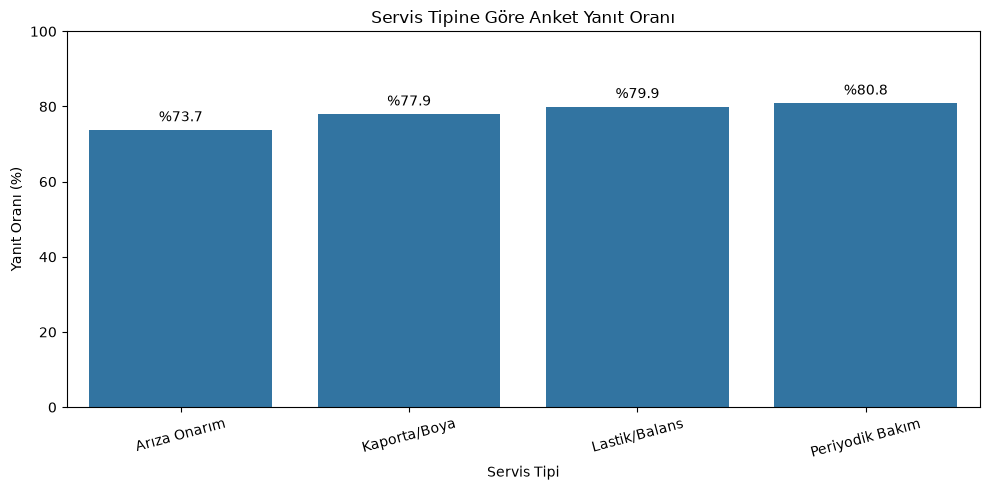

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=tip_memnuniyet,
    x="servis_tipi",
    y="yanit_orani_yuzde"
)

plt.title("Servis Tipine Göre Anket Yanıt Oranı")
plt.xlabel("Servis Tipi")
plt.ylabel("Yanıt Oranı (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15)

# Sütunların üzerine oran değerlerini ekle
for bar in ax.patches:
    yukseklik = bar.get_height()
    ax.annotate(
        f"%{yukseklik:.1f}",
        (bar.get_x() + bar.get_width() / 2, yukseklik),
        ha="center",
        va="bottom",
        xytext=(0, 4),
        textcoords="offset points"
    )

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "ciktilar" / "analiz" / "02_servis_tipi_yanit_orani.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [13]:
# Servis tutarı incelemesi

tutar_inceleme = pd.to_numeric(
    servis_ham["tutar"],
    errors="coerce"
)

print("SERVİS TUTARI VERİ KALİTESİ İNCELEMESİ")
print("-" * 55)

print("Orijinal veri tipi:", servis_ham["tutar"].dtype)
print("Toplam kayıt:", len(servis_ham))
print("Eksik değer:", servis_ham["tutar"].isna().sum())
print("Sayısala dönüştürülemeyen değer:",
      (servis_ham["tutar"].notna() & tutar_inceleme.isna()).sum())
print("Negatif tutar:", (tutar_inceleme < 0).sum())
print("Sıfır tutar:", (tutar_inceleme == 0).sum())

print("\nTanımlayıcı istatistikler:")
display(
    tutar_inceleme.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)


print("\nEn düşük 10 tutar:")
dusuk_tutarlar = servis_ham.loc[
    tutar_inceleme.nsmallest(10).index,
    ["kayit_id", "arac_id", "servis_tipi",
     "servis_tarihi", "servis_merkezi", "tutar"]
]
display(dusuk_tutarlar)


print("\nEn yüksek 10 tutar:")
yuksek_tutarlar = servis_ham.loc[
    tutar_inceleme.nlargest(10).index,
    ["kayit_id", "arac_id", "servis_tipi",
     "servis_tarihi", "servis_merkezi", "tutar"]
]
display(yuksek_tutarlar)

SERVİS TUTARI VERİ KALİTESİ İNCELEMESİ
-------------------------------------------------------
Orijinal veri tipi: float64
Toplam kayıt: 32770
Eksik değer: 0
Sayısala dönüştürülemeyen değer: 0
Negatif tutar: 150
Sıfır tutar: 223

Tanımlayıcı istatistikler:


count      32770.00
mean       12999.48
std        37063.98
min       -47222.59
25%         7431.54
50%         9905.42
75%        13165.14
90%        23416.35
95%        29544.33
99%        41316.72
max      2886854.22
Name: tutar, dtype: float64


En düşük 10 tutar:


,kayit_id,arac_id,servis_tipi,servis_tarihi,servis_merkezi,tutar
31586,1874,500276,Kaporta/Boya,2023-05-16,SM-Maslak,-47222.59
18268,20219,503000,Kaporta/Boya,2022-02-02,SM-Ankara1,-44240.88
31514,7481,501110,Arıza Onarım,2022-04-15,SM-Ankara1,-40082.47
32008,23007,503401,Arıza Onarım,03/10/2025,SM-Maslak,-38788.45
16886,5687,500841,Kaporta/Boya,2024-10-01,SM-Bursa1,-36733.94
20465,12365,501818,Arıza Onarım,15/06/2022,SM-Maslak,-36044.76
2093,27620,504089,Kaporta/Boya,2025-08-02,SM-Kadıköy,-33949.55
18293,3735,500544,Kaporta/Boya,2024-12-27,SM-Bursa1,-33664.65
9624,17113,502528,Arıza Onarım,2025-12-12,SM-Maslak,-30579.83
14619,23875,503525,Arıza Onarım,2022-11-03,SM-Maslak,-30543.42



En yüksek 10 tutar:


,kayit_id,arac_id,servis_tipi,servis_tarihi,servis_merkezi,tutar
30495,8911,501320,Arıza Onarım,2022-03-08,SM-Bursa1,2.886854e+06
1418,24388,503603,Kaporta/Boya,2023-06-28,SM-Antalya1,2.350557e+06
25312,1519,500227,Arıza Onarım,2025-04-11,SM-Ankara1,2.104598e+06
1811,16269,502393,Arıza Onarım,2024-07-09,SM-Maslak,1.828645e+06
5796,11511,501703,Arıza Onarım,2025-06-20 00:00:00,SM-Antalya1,1.467504e+06
4802,393,500063,Periyodik Bakım,2025-11-29,SM-Kocaeli1,1.176961e+06
4966,32388,504776,Arıza Onarım,2023-11-20,SM-Maslak,1.164323e+06
29480,22737,503360,Arıza Onarım,2025-04-17,SM-Maslak,1.144048e+06
23925,16022,502358,Periyodik Bakım,2022-04-10,SM-Ankara1,1.108038e+06
29422,14180,502077,Arıza Onarım,27/03/2022,SM-Kocaeli1,1.008006e+06


**Negatif tutar**	150,	İade/düzeltme olabilir

**Sıfır tutar**	223,	Ücretsiz işlem veya kayıt sorunu olabilir

In [14]:
# 1. Negatif ve sıfır tutarların servis tipine göre dağılımı
tutar_tip_analizi = (
    servis_ham.assign(tutar_sayisal=tutar_inceleme)
    .groupby("servis_tipi")
    .agg(
        toplam_kayit=("kayit_id", "count"),
        negatif_tutar=("tutar_sayisal", lambda x: (x < 0).sum()),
        sifir_tutar=("tutar_sayisal", lambda x: (x == 0).sum()),
        ortalama_tutar=("tutar_sayisal", "mean"),
        medyan_tutar=("tutar_sayisal", "median"),
        maksimum_tutar=("tutar_sayisal", "max")
    )
    .round(2)
)

print("SERVİS TİPİNE GÖRE TUTAR ANALİZİ")
display(tutar_tip_analizi)


# 2. IQR yöntemiyle istatistiksel uç değer sınırı
q1 = tutar_inceleme.quantile(0.25)
q3 = tutar_inceleme.quantile(0.75)
iqr = q3 - q1

alt_sinir = q1 - 1.5 * iqr
ust_sinir = q3 + 1.5 * iqr

print("\nIQR UÇ DEĞER ANALİZİ")
print("-" * 45)
print(f"Q1: {q1:.2f}")
print(f"Q3: {q3:.2f}")
print(f"IQR: {iqr:.2f}")
print(f"Alt sınır: {alt_sinir:.2f}")
print(f"Üst sınır: {ust_sinir:.2f}")

print("Alt sınırın altındaki kayıt:", (tutar_inceleme < alt_sinir).sum())
print("Üst sınırın üzerindeki kayıt:", (tutar_inceleme > ust_sinir).sum())


# 3. Üst sınırı aşan en yüksek 20 kayıt
print("\nIQR ÜST SINIRINI AŞAN EN YÜKSEK 20 KAYIT")

uc_degerler = servis_ham.loc[
    tutar_inceleme > ust_sinir,
    ["kayit_id", "arac_id", "servis_tipi",
     "servis_tarihi", "servis_merkezi", "tutar"]
].copy()

display(uc_degerler.nlargest(20, "tutar"))

SERVİS TİPİNE GÖRE TUTAR ANALİZİ


,toplam_kayit,negatif_tutar,sifir_tutar,ortalama_tutar,medyan_tutar,maksimum_tutar
servis_tipi,,,,,,
Arıza Onarım,6843,27,49,19733.16,17689.56,2886854.22
Kaporta/Boya,2294,13,16,26798.53,25489.12,2350557.43
Lastik/Balans,3320,12,23,6714.39,6130.08,763152.10
Periyodik Bakım,20313,98,135,10199.94,9474.37,1176960.83



IQR UÇ DEĞER ANALİZİ
---------------------------------------------
Q1: 7431.53
Q3: 13165.15
IQR: 5733.61
Alt sınır: -1168.88
Üst sınır: 21765.56
Alt sınırın altındaki kayıt: 150
Üst sınırın üzerindeki kayıt: 3832

IQR ÜST SINIRINI AŞAN EN YÜKSEK 20 KAYIT


,kayit_id,arac_id,servis_tipi,servis_tarihi,servis_merkezi,tutar
30495,8911,501320,Arıza Onarım,2022-03-08,SM-Bursa1,2.886854e+06
1418,24388,503603,Kaporta/Boya,2023-06-28,SM-Antalya1,2.350557e+06
25312,1519,500227,Arıza Onarım,2025-04-11,SM-Ankara1,2.104598e+06
1811,16269,502393,Arıza Onarım,2024-07-09,SM-Maslak,1.828645e+06
5796,11511,501703,Arıza Onarım,2025-06-20 00:00:00,SM-Antalya1,1.467504e+06
4802,393,500063,Periyodik Bakım,2025-11-29,SM-Kocaeli1,1.176961e+06
4966,32388,504776,Arıza Onarım,2023-11-20,SM-Maslak,1.164323e+06
29480,22737,503360,Arıza Onarım,2025-04-17,SM-Maslak,1.144048e+06
23925,16022,502358,Periyodik Bakım,2022-04-10,SM-Ankara1,1.108038e+06
29422,14180,502077,Arıza Onarım,27/03/2022,SM-Kocaeli1,1.008006e+06


**Karar:** Negatif ve sıfır tutarlı kayıtları şimdilik koruyoruz. İade, düzeltme veya ücretsiz işlem olasılıklarını doğrulayacak ek bir açıklama alanımız bulunmuyor.

Negatif, sıfır ve yüksek tutarlı kayıtların hiçbirini silmiyoruz. Yüksek tutarların gerçekten veri hatası olup olmadığını henüz kanıtlayamadık.

In [15]:
# Servis tipine özel IQR analizi

tip_bazli_iqr = []

for servis_tipi, grup in servis_ham.assign(
    tutar_sayisal=tutar_inceleme
).groupby("servis_tipi"):

    q1 = grup["tutar_sayisal"].quantile(0.25)
    q3 = grup["tutar_sayisal"].quantile(0.75)
    iqr = q3 - q1

    alt = q1 - 1.5 * iqr
    ust = q3 + 1.5 * iqr

    tip_bazli_iqr.append({
        "servis_tipi": servis_tipi,
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "IQR": round(iqr, 2),
        "alt_sinir": round(alt, 2),
        "ust_sinir": round(ust, 2),
        "alt_uc_deger": (grup["tutar_sayisal"] < alt).sum(),
        "ust_uc_deger": (grup["tutar_sayisal"] > ust).sum()
    })

tip_bazli_iqr = pd.DataFrame(tip_bazli_iqr)

print("SERVİS TİPİNE ÖZEL IQR SONUÇLARI")
display(tip_bazli_iqr)


print("\nYÜKSEK TUTAR EŞİKLERİ")
for esik in [100_000, 500_000, 1_000_000]:
    adet = (tutar_inceleme > esik).sum()
    print(f"{esik:>10,} üzerindeki kayıt: {adet}")



print("\n100.000 ÜZERİNDEKİ KAYITLAR")

yuksek_tutar_detay = servis_ham.loc[
    tutar_inceleme > 100_000,
    ["kayit_id", "arac_id", "servis_tipi",
     "servis_tarihi", "servis_merkezi", "tutar"]
].sort_values("tutar", ascending=False)

display(yuksek_tutar_detay)

SERVİS TİPİNE ÖZEL IQR SONUÇLARI


,servis_tipi,Q1,Q3,IQR,alt_sinir,ust_sinir,alt_uc_deger,ust_uc_deger
0,Arıza Onarım,11222.42,24372.62,13150.20,-8502.88,44097.92,25,27
1,Kaporta/Boya,17262.90,34276.20,17013.31,-8257.06,59796.17,13,11
2,Lastik/Balans,4886.56,7393.02,2506.46,1126.87,11152.71,42,14
3,Periyodik Bakım,7660.94,11239.77,3578.83,2292.69,16608.02,295,90



YÜKSEK TUTAR EŞİKLERİ
   100,000 üzerindeki kayıt: 43
   500,000 üzerindeki kayıt: 32
 1,000,000 üzerindeki kayıt: 10

100.000 ÜZERİNDEKİ KAYITLAR


,kayit_id,arac_id,servis_tipi,servis_tarihi,servis_merkezi,tutar
30495,8911,501320,Arıza Onarım,2022-03-08,SM-Bursa1,2.886854e+06
1418,24388,503603,Kaporta/Boya,2023-06-28,SM-Antalya1,2.350557e+06
25312,1519,500227,Arıza Onarım,2025-04-11,SM-Ankara1,2.104598e+06
1811,16269,502393,Arıza Onarım,2024-07-09,SM-Maslak,1.828645e+06
5796,11511,501703,Arıza Onarım,2025-06-20 00:00:00,SM-Antalya1,1.467504e+06
4802,393,500063,Periyodik Bakım,2025-11-29,SM-Kocaeli1,1.176961e+06
4966,32388,504776,Arıza Onarım,2023-11-20,SM-Maslak,1.164323e+06
29480,22737,503360,Arıza Onarım,2025-04-17,SM-Maslak,1.144048e+06
23925,16022,502358,Periyodik Bakım,2022-04-10,SM-Ankara1,1.108038e+06
29422,14180,502077,Arıza Onarım,27/03/2022,SM-Kocaeli1,1.008006e+06


|Bulgu	|Yapılan işlem|	Gerekçe|
|-------|------|------|
150 negatif tutar|	Korunacak, ayrıca işaretlenecek|İade veya düzeltme olabilir
223 sıfır tutar|	Korunacak, ayrıca işaretlenecek|	Ücretsiz işlem veya özel kayıt olabilir
IQR sınırlarını aşan tutarlar	|Silinmeyecek|	İstatistiksel uç değer, otomatik olarak hata değildir
43 adet 100.000 üzeri kayıt	|İnceleme için ayrılacak	|büyük tutarlar
10 adet 1.000.000 üzeri kayıt|	Öncelikli doğrulama adayı	|Veri giriş hatası veya olağan dışı işlem olabilir

In [16]:
# Negatif ve sıfır servis tutarlarının dağılımı

tutar_ozel_durum = servis_ham.assign(
    tutar_sayisal=tutar_inceleme
).assign(
    tutar_durumu=lambda df: np.select(
        [
            df["tutar_sayisal"] < 0,
            df["tutar_sayisal"] == 0
        ],
        [
            "Negatif",
            "Sıfır"
        ],
        default="Pozitif"
    )
)

tutar_durum_ozeti = (
    tutar_ozel_durum
    .groupby(["servis_tipi", "tutar_durumu"])
    .size()
    .unstack(fill_value=0)
)

print("SERVİS TİPİNE GÖRE NEGATİF VE SIFIR TUTARLAR")
display(tutar_durum_ozeti)

print("\nSERVİS MERKEZİNE GÖRE NEGATİF VE SIFIR TUTARLAR")

merkez_tutar_ozeti = (
    tutar_ozel_durum
    .groupby(["servis_merkezi", "tutar_durumu"])
    .size()
    .unstack(fill_value=0)
)

display(merkez_tutar_ozeti)

SERVİS TİPİNE GÖRE NEGATİF VE SIFIR TUTARLAR


tutar_durumu,Negatif,Pozitif,Sıfır
servis_tipi,,,
Arıza Onarım,27,6767,49
Kaporta/Boya,13,2265,16
Lastik/Balans,12,3285,23
Periyodik Bakım,98,20080,135



SERVİS MERKEZİNE GÖRE NEGATİF VE SIFIR TUTARLAR


tutar_durumu,Negatif,Pozitif,Sıfır
servis_merkezi,,,
SM-Ankara1,14,4226,23
SM-Antalya1,24,2899,22
SM-Bursa1,17,3153,17
SM-Kadıköy,28,5356,44
SM-Kocaeli1,8,2683,20
SM-Maslak,46,10369,63
SM-İzmir1,13,3711,34


In [17]:
# Negatif tutarlı servis kayıtlarının detayları

negatif_tutar_detay = servis_ham.loc[
    tutar_inceleme < 0,
    [
        "kayit_id",
        "arac_id",
        "servis_tipi",
        "servis_tarihi",
        "servis_merkezi",
        "tutar"
    ]
].sort_values("tutar")

print("NEGATİF TUTARLI KAYITLAR")
print("Toplam kayıt:", len(negatif_tutar_detay))

display(negatif_tutar_detay)

NEGATİF TUTARLI KAYITLAR
Toplam kayıt: 150


,kayit_id,arac_id,servis_tipi,servis_tarihi,servis_merkezi,tutar
31586,1874,500276,Kaporta/Boya,2023-05-16,SM-Maslak,-47222.59
18268,20219,503000,Kaporta/Boya,2022-02-02,SM-Ankara1,-44240.88
31514,7481,501110,Arıza Onarım,2022-04-15,SM-Ankara1,-40082.47
32008,23007,503401,Arıza Onarım,03/10/2025,SM-Maslak,-38788.45
16886,5687,500841,Kaporta/Boya,2024-10-01,SM-Bursa1,-36733.94
...,...,...,...,...,...,...
194,24369,503598,Periyodik Bakım,2026-04-17,SM-Maslak,-4678.82
29340,2442,500351,Periyodik Bakım,2023-04-06,SM-Kocaeli1,-4667.86
23958,9399,501390,Periyodik Bakım,13/05/2023,SM-Antalya1,-4525.61
4078,9168,501357,Lastik/Balans,2023-03-09,SM-Antalya1,-3174.50


Negatif tutarlar şu olasılıkları barındırıyor:
- İade veya ücret düzeltmesi,
- Garanti kapsamında yapılan muhasebe işlemi,
- İptal ya da ters kayıt,
- Veri üretimi veya veri giriş hatası.

In [18]:
# Sıfır tutarlı servis kayıtlarının detayları

sifir_tutar_detay = servis_ham.loc[
    tutar_inceleme == 0,
    [
        "kayit_id",
        "arac_id",
        "servis_tipi",
        "servis_tarihi",
        "servis_merkezi",
        "tutar"
    ]
].sort_values(["servis_tipi", "servis_merkezi"])

print("SIFIR TUTARLI KAYITLAR")
print("Toplam kayıt:", len(sifir_tutar_detay))

display(sifir_tutar_detay)

SIFIR TUTARLI KAYITLAR
Toplam kayıt: 223


,kayit_id,arac_id,servis_tipi,servis_tarihi,servis_merkezi,tutar
3618,30572,504516,Arıza Onarım,2026-04-15,SM-Ankara1,0.0
4227,31530,504654,Arıza Onarım,2023-09-24,SM-Ankara1,0.0
26410,9,500002,Arıza Onarım,2023-03-05,SM-Ankara1,0.0
28981,19467,502891,Arıza Onarım,2025-01-29,SM-Ankara1,0.0
31250,17048,502518,Arıza Onarım,08/08/2023,SM-Ankara1,0.0
...,...,...,...,...,...,...
25347,7024,501047,Periyodik Bakım,2024-12-07,SM-İzmir1,0.0
26483,6430,500953,Periyodik Bakım,2022-12-29,SM-İzmir1,0.0
28106,531,500084,Periyodik Bakım,2023-03-28 00:00:00,SM-İzmir1,0.0
31779,413,500068,Periyodik Bakım,2022-10-31,SM-İzmir1,0.0


Negatif ve sıfır tutarları ileride analiz veya modelleme aşamasında kullanım biçimi ayrıca değerlendirilecek.

In [20]:


kategorik_sutunlar = [
    "servis_tipi",
    "servis_merkezi"
]

print("KATEGORİK SÜTUNLAR")

for sutun in kategorik_sutunlar:
    print(f"\n{'-' * 55}")
    print(f"Sütun: {sutun}")
    print("Eksik değer:", servis_ham[sutun].isna().sum())
    print("Benzersiz değer sayısı:", servis_ham[sutun].nunique())

    display(
        servis_ham[sutun]
        .value_counts(dropna=False)
        .to_frame("adet")
    )

KATEGORİK SÜTUNLAR

-------------------------------------------------------
Sütun: servis_tipi
Eksik değer: 0
Benzersiz değer sayısı: 4


,adet
servis_tipi,
Periyodik Bakım,20313
Arıza Onarım,6843
Lastik/Balans,3320
Kaporta/Boya,2294



-------------------------------------------------------
Sütun: servis_merkezi
Eksik değer: 0
Benzersiz değer sayısı: 7


,adet
servis_merkezi,
SM-Maslak,10478
SM-Kadıköy,5428
SM-Ankara1,4263
SM-İzmir1,3758
SM-Bursa1,3187
SM-Antalya1,2945
SM-Kocaeli1,2711


In [21]:
# Servis kilometresi incelemesi

km_inceleme = pd.to_numeric(
    servis_ham["km"],
    errors="coerce"
)

print("SERVİS KİLOMETRESİ VERİ KALİTESİ İNCELEMESİ")
print("-" * 55)

print("Orijinal veri tipi:", servis_ham["km"].dtype)
print("Toplam kayıt:", len(servis_ham))
print("Eksik değer:", servis_ham["km"].isna().sum())
print(
    "Sayısala dönüştürülemeyen değer:",
    (servis_ham["km"].notna() & km_inceleme.isna()).sum()
)
print("Negatif kilometre:", (km_inceleme < 0).sum())
print("Sıfır kilometre:", (km_inceleme == 0).sum())

print("\nTanımlayıcı istatistikler:")
display(
    km_inceleme.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)

print("\nEn düşük 10 kilometre:")
display(
    servis_ham.loc[
        km_inceleme.nsmallest(10).index,
        ["kayit_id", "arac_id", "servis_tipi", "servis_tarihi", "km"]
    ]
)

print("\nEn yüksek 10 kilometre:")
display(
    servis_ham.loc[
        km_inceleme.nlargest(10).index,
        ["kayit_id", "arac_id", "servis_tipi", "servis_tarihi", "km"]
    ]
)

# IQR analizi
q1_km = km_inceleme.quantile(0.25)
q3_km = km_inceleme.quantile(0.75)
iqr_km = q3_km - q1_km

alt_km = q1_km - 1.5 * iqr_km
ust_km = q3_km + 1.5 * iqr_km

print("\nKİLOMETRE IQR ANALİZİ")
print("-" * 45)
print(f"Q1: {q1_km:.2f}")
print(f"Q3: {q3_km:.2f}")
print(f"IQR: {iqr_km:.2f}")
print(f"Alt sınır: {alt_km:.2f}")
print(f"Üst sınır: {ust_km:.2f}")
print("Alt uç değer sayısı:", (km_inceleme < alt_km).sum())
print("Üst uç değer sayısı:", (km_inceleme > ust_km).sum())

SERVİS KİLOMETRESİ VERİ KALİTESİ İNCELEMESİ
-------------------------------------------------------
Orijinal veri tipi: int64
Toplam kayıt: 32770
Eksik değer: 0
Sayısala dönüştürülemeyen değer: 0
Negatif kilometre: 42
Sıfır kilometre: 0

Tanımlayıcı istatistikler:


count    32770.00
mean      1264.10
std        709.74
min      -2976.00
25%        670.00
50%       1188.00
75%       1786.00
90%       2263.00
95%       2500.55
99%       2918.00
max       3938.00
Name: km, dtype: float64


En düşük 10 kilometre:


,kayit_id,arac_id,servis_tipi,servis_tarihi,km
9460,4961,500724,Periyodik Bakım,2025-06-16 00:00:00,-2976
12179,4961,500724,Periyodik Bakım,2025-06-16 00:00:00,-2976
11680,18622,502762,Kaporta/Boya,2025-04-10,-2761
4230,31088,504589,Arıza Onarım,2025-11-11,-2387
2801,1302,500197,Lastik/Balans,2025-08-06,-2296
27527,31849,504697,Periyodik Bakım,2025-05-01,-2285
1064,10872,501607,Periyodik Bakım,2026-03-21,-2282
14374,23034,503405,Arıza Onarım,2025-10-08,-2087
14579,5397,500798,Periyodik Bakım,08/01/2026,-2048
29226,4203,500612,Periyodik Bakım,2025-07-27,-2044



En yüksek 10 kilometre:


,kayit_id,arac_id,servis_tipi,servis_tarihi,km
7233,30472,504502,Arıza Onarım,2026-05-29,3938
19487,16539,502439,Periyodik Bakım,2026-06-11,3753
18970,18170,502692,Arıza Onarım,28.06.2026,3744
14899,5704,500844,Periyodik Bakım,22/06/2026,3737
15899,60,500008,Periyodik Bakım,2026-04-30,3682
25950,29219,504319,Periyodik Bakım,2026-01-16,3644
9407,11677,501723,Periyodik Bakım,2026-06-02,3549
21352,15111,502218,Periyodik Bakım,2026-06-29,3547
19677,29851,504410,Periyodik Bakım,2025-10-13,3545
29149,14410,502108,Periyodik Bakım,08/05/2026,3540



KİLOMETRE IQR ANALİZİ
---------------------------------------------
Q1: 670.00
Q3: 1786.00
IQR: 1116.00
Alt sınır: -1004.00
Üst sınır: 3460.00
Alt uç değer sayısı: 22
Üst uç değer sayısı: 19


In [22]:
# Negatif kilometre kayıtlarının detaylı incelenmesi

negatif_km_detay = servis_ham.loc[
    km_inceleme < 0,
    [
        "kayit_id",
        "arac_id",
        "servis_tipi",
        "servis_tarihi",
        "servis_merkezi",
        "km"
    ]
].sort_values("km")

print("NEGATİF KİLOMETRELİ SERVİS KAYITLARI")
print("Toplam kayıt:", len(negatif_km_detay))

display(negatif_km_detay)

NEGATİF KİLOMETRELİ SERVİS KAYITLARI
Toplam kayıt: 42


,kayit_id,arac_id,servis_tipi,servis_tarihi,servis_merkezi,km
9460,4961,500724,Periyodik Bakım,2025-06-16 00:00:00,SM-Antalya1,-2976
12179,4961,500724,Periyodik Bakım,2025-06-16 00:00:00,SM-Antalya1,-2976
11680,18622,502762,Kaporta/Boya,2025-04-10,SM-Maslak,-2761
4230,31088,504589,Arıza Onarım,2025-11-11,SM-Maslak,-2387
2801,1302,500197,Lastik/Balans,2025-08-06,SM-Antalya1,-2296
27527,31849,504697,Periyodik Bakım,2025-05-01,SM-Kadıköy,-2285
1064,10872,501607,Periyodik Bakım,2026-03-21,SM-Kadıköy,-2282
14374,23034,503405,Arıza Onarım,2025-10-08,SM-İzmir1,-2087
14579,5397,500798,Periyodik Bakım,08/01/2026,SM-Ankara1,-2048
29226,4203,500612,Periyodik Bakım,2025-07-27,SM-Maslak,-2044


**Karar:** Negatif kilometreleri henüz silmiyoruz. Temizleme aşamasında geçersiz değer olarak işaretleyip nasıl ele alacağımıza karar vereceğiz. Pozitif uç değerleri ise araç bazında tarih sırasıyla incelemeden hatalı saymayacağız.

In [23]:
# Araç bazında kilometre tutarlılığı

km_arac_inceleme = servis_ham.copy()

# Doğrulanmış açık tarih formatlarıyla dönüşüm
tarih = km_arac_inceleme["servis_tarihi"].astype("string").str.strip()

km_arac_inceleme["servis_tarihi_dt"] = pd.NaT

tarih_formatlari = [
    ("%Y-%m-%d %H:%M:%S", tarih.str.fullmatch(r"\d{4}-\d{2}-\d{2} \d{2}:\d{2}:\d{2}")),
    ("%Y-%m-%d", tarih.str.fullmatch(r"\d{4}-\d{2}-\d{2}")),
    ("%d/%m/%Y", tarih.str.fullmatch(r"\d{2}/\d{2}/\d{4}")),
    ("%d.%m.%Y", tarih.str.fullmatch(r"\d{2}\.\d{2}\.\d{4}"))
]

for tarih_formati, maske in tarih_formatlari:
    km_arac_inceleme.loc[maske, "servis_tarihi_dt"] = pd.to_datetime(
        tarih.loc[maske],
        format=tarih_formati,
        errors="coerce"
    )

km_arac_inceleme["km_sayisal"] = pd.to_numeric(
    km_arac_inceleme["km"],
    errors="coerce"
)

# Birebir tekrarlı kayıtları yalnızca inceleme kopyasında kaldır
km_arac_inceleme = km_arac_inceleme.drop_duplicates(
    subset="kayit_id"
)

# Araç ve tarih sıralaması
km_arac_inceleme = km_arac_inceleme.sort_values(
    ["arac_id", "servis_tarihi_dt", "kayit_id"]
)

# Bir önceki servis kaydının kilometresi
km_arac_inceleme["onceki_km"] = (
    km_arac_inceleme.groupby("arac_id")["km_sayisal"].shift(1)
)

km_arac_inceleme["km_degisim"] = (
    km_arac_inceleme["km_sayisal"]
    - km_arac_inceleme["onceki_km"]
)

# Tarih sırasına göre kilometresi azalan kayıtlar
azalan_km = km_arac_inceleme[
    km_arac_inceleme["km_degisim"] < 0
].copy()

print("ARAÇ BAZINDA KİLOMETRE TUTARLILIĞI")
print("-" * 55)

print("Tekrarlı kaydı çıkarılmış toplam kayıt:", len(km_arac_inceleme))
print("Tarih dönüşümü başarısız kayıt:",
      km_arac_inceleme["servis_tarihi_dt"].isna().sum())
print("Negatif kilometre kayıt sayısı:",
      (km_arac_inceleme["km_sayisal"] < 0).sum())
print("Tarih sırasına göre kilometresi azalan kayıt:", len(azalan_km))
print("Kilometresi azalan farklı araç sayısı:",
      azalan_km["arac_id"].nunique())

print("\nKilometresi azalan ilk 20 kayıt:")
display(
    azalan_km[
        ["arac_id", "kayit_id", "servis_tarihi_dt",
         "onceki_km", "km_sayisal", "km_degisim"]
    ].head(20)
)

print("\nEn büyük kilometre düşüşleri:")
display(
    azalan_km.nsmallest(
        10, "km_degisim"
    )[
        ["arac_id", "kayit_id", "servis_tarihi_dt",
         "onceki_km", "km_sayisal", "km_degisim"]
    ]
)

ARAÇ BAZINDA KİLOMETRE TUTARLILIĞI
-------------------------------------------------------
Tekrarlı kaydı çıkarılmış toplam kayıt: 32460
Tarih dönüşümü başarısız kayıt: 0
Negatif kilometre kayıt sayısı: 40
Tarih sırasına göre kilometresi azalan kayıt: 340
Kilometresi azalan farklı araç sayısı: 331

Kilometresi azalan ilk 20 kayıt:


,arac_id,kayit_id,servis_tarihi_dt,onceki_km,km_sayisal,km_degisim
15910,500054,344,2024-07-21,791.0,574,-217.0
19358,500055,352,2024-11-11,1307.0,433,-874.0
8072,500075,458,2023-12-05,1014.0,813,-201.0
18347,500088,563,2024-02-10,872.0,653,-219.0
8300,500094,599,2024-03-18,889.0,506,-383.0
20781,500107,687,2024-04-02,1547.0,637,-910.0
21938,500121,797,2024-06-20,1472.0,-1857,-3329.0
22111,500131,861,2023-09-08,1309.0,615,-694.0
24851,500140,910,2023-04-25,648.0,388,-260.0
9135,500163,1072,2024-02-16,901.0,478,-423.0



En büyük kilometre düşüşleri:


,arac_id,kayit_id,servis_tarihi_dt,onceki_km,km_sayisal,km_degisim
9460,500724,4961,2025-06-16,2666.0,-2976,-5642.0
11680,502762,18622,2025-04-10,2365.0,-2761,-5126.0
4230,504589,31088,2025-11-11,1912.0,-2387,-4299.0
1064,501607,10872,2026-03-21,2005.0,-2282,-4287.0
2801,500197,1302,2025-08-06,1856.0,-2296,-4152.0
27527,504697,31849,2025-05-01,1747.0,-2285,-4032.0
21248,500272,1844,2025-08-10,1940.0,-2011,-3951.0
14374,503405,23034,2025-10-08,1845.0,-2087,-3932.0
29226,500612,4203,2025-07-27,1815.0,-2044,-3859.0
14579,500798,5397,2026-01-08,1772.0,-2048,-3820.0


**karar:** Negatif kilometre değerleri, mantıksal olarak geçersiz değerler şeklinde işaretlenecektir. Araç bazında tarih sırasına göre kilometre değerinde azalma görülen kayıtlar ise ayrı bir tutarsızlık göstergesi olarak raporlanacaktır. Bu kayıtların gerçek kilometre değerleri mevcut veriden doğrulanamadığı için otomatik düzeltme, sıfırla değiştirme veya silme işlemi yapılmayacaktır. İleri analizlerde bu kayıtların nasıl ele alınacağı analiz amacına göre ayrıca değerlendirilecektir.

In [26]:
# Kilometre Düşüşlerinin Türlerine Göre Sınıflandırılması
# Tüm servis kayıtlarında bir önceki servis tarihini hesapla
km_arac_inceleme["onceki_servis_tarihi"] = (
    km_arac_inceleme.groupby("arac_id")["servis_tarihi_dt"].shift(1)
)

# Kilometresi azalan kayıtları yeniden oluştur
azalan_km = km_arac_inceleme[
    km_arac_inceleme["km_degisim"] < 0
].copy()


# Aynı gün gerçekleşen kilometre düşüşleri
ayni_gun_dusus = (
    azalan_km["servis_tarihi_dt"]
    == azalan_km["onceki_servis_tarihi"]
).sum()

# Negatif kilometre kontrolleri
negatif_mevcut = (azalan_km["km_sayisal"] < 0).sum()
negatif_onceki = (azalan_km["onceki_km"] < 0).sum()

# Farklı tarihlerde, iki kilometre değeri de negatif değilken düşüş
pozitif_tarihsel_dusus = azalan_km[
    (azalan_km["servis_tarihi_dt"] >
     azalan_km["onceki_servis_tarihi"])
    & (azalan_km["km_sayisal"] >= 0)
    & (azalan_km["onceki_km"] >= 0)
]

print("KİLOMETRE DÜŞÜŞLERİNİN AYRINTILI ANALİZİ")
print("-" * 55)

print("Toplam kilometre düşüşü:", len(azalan_km))
print("Aynı gün içindeki düşüş:", int(ayni_gun_dusus))
print("Mevcut kilometresi negatif olan düşüş:", int(negatif_mevcut))
print("Önceki kilometresi negatif olan düşüş:", int(negatif_onceki))
print(
    "Farklı tarihlerde, iki kilometre de negatif değilken düşüş:",
    len(pozitif_tarihsel_dusus)
)

print("\nNegatif olmayan kilometrelerde farklı tarihler arasındaki en büyük 10 düşüş:")

display(
    pozitif_tarihsel_dusus.nsmallest(
        10, "km_degisim"
    )[
        ["arac_id", "kayit_id", "servis_tarihi_dt",
         "onceki_km", "km_sayisal", "km_degisim"]
    ]
)

KİLOMETRE DÜŞÜŞLERİNİN AYRINTILI ANALİZİ
-------------------------------------------------------
Toplam kilometre düşüşü: 340
Aynı gün içindeki düşüş: 0
Mevcut kilometresi negatif olan düşüş: 30
Önceki kilometresi negatif olan düşüş: 0
Farklı tarihlerde, iki kilometre de negatif değilken düşüş: 310

Negatif olmayan kilometrelerde farklı tarihler arasındaki en büyük 10 düşüş:


,arac_id,kayit_id,servis_tarihi_dt,onceki_km,km_sayisal,km_degisim
13512,501365,9239,2026-05-11,2373.0,695,-1678.0
29633,500277,1891,2026-02-21,2528.0,913,-1615.0
2866,500323,2239,2026-02-21,2353.0,743,-1610.0
11731,503162,21316,2025-10-28,2497.0,921,-1576.0
5819,500591,4065,2026-03-11,2521.0,955,-1566.0
26717,501131,7676,2026-05-18,2168.0,647,-1521.0
6003,503633,24590,2025-09-23,2132.0,627,-1505.0
4896,504242,28660,2026-01-31,2309.0,811,-1498.0
16828,500582,3996,2026-05-04,2500.0,1017,-1483.0
25115,504384,29640,2025-03-21,2416.0,959,-1457.0


**Karar:** Negatif kilometre değerleri geçersiz değer olarak işaretlenecektir. Araç bazında yapılan incelemede 340 kilometre düşüşü tespit edilmiştir. Bunların 30'unda mevcut kilometre değeri negatif, 310'unda ise hem önceki hem mevcut kilometre negatif olmamasına rağmen kilometre değeri azalmıştır. Bu kayıtlar veri tutarsızlığı göstergesi olarak ayrı değerlendirilecektir. Gerçek kilometre değerleri doğrulanamadığı için otomatik düzeltme veya silme yapılmayacaktır.

In [27]:
# En büyük 10 düşüşün gerçekleştiği araçları belirle
incelenecek_araclar = (
    pozitif_tarihsel_dusus
    .nsmallest(10, "km_degisim")["arac_id"]
    .unique()
)

# Bu araçların tüm servis geçmişlerini görüntüle
arac_gecmisleri = km_arac_inceleme[
    km_arac_inceleme["arac_id"].isin(incelenecek_araclar)
].sort_values(
    ["arac_id", "servis_tarihi_dt"]
)

print("EN BÜYÜK KİLOMETRE DÜŞÜŞLERİNİN GERÇEKLEŞTİĞİ ARAÇLAR")
print("-" * 65)
print("İncelenen farklı araç sayısı:", len(incelenecek_araclar))

display(
    arac_gecmisleri[
        [
            "arac_id",
            "kayit_id",
            "servis_tarihi_dt",
            "onceki_km",
            "km_sayisal",
            "km_degisim"
        ]
    ]
)

EN BÜYÜK KİLOMETRE DÜŞÜŞLERİNİN GERÇEKLEŞTİĞİ ARAÇLAR
-----------------------------------------------------------------
İncelenen farklı araç sayısı: 10


,arac_id,kayit_id,servis_tarihi_dt,onceki_km,km_sayisal,km_degisim
21382,500277,1882,2022-03-18,NaN,382,NaN
16224,500277,1883,2022-10-30,382.0,699,317.0
12508,500277,1884,2023-03-25,699.0,1028,329.0
10945,500277,1885,2023-09-28,1028.0,1289,261.0
1641,500277,1886,2024-01-13,1289.0,1595,306.0
...,...,...,...,...,...,...
28384,504384,29639,2024-12-05,2357.0,2416,59.0
25115,504384,29640,2025-03-21,2416.0,959,-1457.0
25476,504384,29641,2025-08-15,959.0,2854,1895.0
16569,504384,29642,2025-11-23,2854.0,2962,108.0


In [28]:
# Pozitif kilometre değerleri arasındaki tarihsel düşüşler

pozitif_tarihsel_dusus = km_arac_inceleme[
    (km_arac_inceleme["km_degisim"] < 0)
    & (km_arac_inceleme["onceki_km"] >= 0)
    & (km_arac_inceleme["km_sayisal"] >= 0)
].copy()

print("Pozitif olmayan değil, negatif olmayan kilometreler arasındaki düşüş")
print("-" * 60)
print("Filtrelenen kayıt sayısı:", len(pozitif_tarihsel_dusus))
print("Farklı araç sayısı:", pozitif_tarihsel_dusus["arac_id"].nunique())

Pozitif olmayan değil, negatif olmayan kilometreler arasındaki düşüş
------------------------------------------------------------
Filtrelenen kayıt sayısı: 310
Farklı araç sayısı: 301


Negatif olmayan kilometre değerleri arasında 310 düşüş kaydı tespit edilmiş ve bu kayıtların 301 farklı araca ait olduğu belirlenmiştir.

In [29]:
# Araç bazında sıralama ve önceki kayıt kontrolleri
kontrol = km_arac_inceleme[
    [
        "arac_id",
        "kayit_id",
        "servis_tarihi_dt",
        "onceki_km",
        "km_sayisal",
        "km_degisim"
    ]
].copy()

kontrol["onceki_tarih"] = (
    km_arac_inceleme.groupby("arac_id")["servis_tarihi_dt"].shift(1)
)

# İki farklı filtre karşılaştırma
filtre_1 = (
    (kontrol["km_degisim"] < 0)
    & (kontrol["onceki_km"] >= 0)
    & (kontrol["km_sayisal"] >= 0)
)

filtre_2 = (
    filtre_1
    & (kontrol["servis_tarihi_dt"] > kontrol["onceki_tarih"])
)

print("Negatif olmayan iki kilometre değeriyle düşüş:", filtre_1.sum())
print("Farklı tarihlerdeki düşüş:", filtre_2.sum())

print("\nİlk 15 düşüş kaydı:")
display(
    kontrol.loc[filtre_2].head(15)
)

Negatif olmayan iki kilometre değeriyle düşüş: 310
Farklı tarihlerdeki düşüş: 310

İlk 15 düşüş kaydı:


,arac_id,kayit_id,servis_tarihi_dt,onceki_km,km_sayisal,km_degisim,onceki_tarih
15910,500054,344,2024-07-21,791.0,574,-217.0,2023-11-08
19358,500055,352,2024-11-11,1307.0,433,-874.0,2024-05-01
8072,500075,458,2023-12-05,1014.0,813,-201.0,2023-03-24
18347,500088,563,2024-02-10,872.0,653,-219.0,2023-07-26
8300,500094,599,2024-03-18,889.0,506,-383.0,2023-08-21
20781,500107,687,2024-04-02,1547.0,637,-910.0,2023-11-11
22111,500131,861,2023-09-08,1309.0,615,-694.0,2022-12-03
24851,500140,910,2023-04-25,648.0,388,-260.0,2022-11-14
9135,500163,1072,2024-02-16,901.0,478,-423.0,2023-05-23
7248,500170,1105,2022-06-24,262.0,198,-64.0,2022-02-28


In [30]:
# Servis türüne göre kilometre düşüşü analizi

servis_turu_ozet = (
    km_arac_inceleme.assign(pozitif_km_dususu=filtre_2)
    .groupby("servis_tipi")
    .agg(
        toplam_kayit=("kayit_id", "count"),
        dusus_kaydi=("pozitif_km_dususu", "sum"),
        toplam_farkli_arac=("arac_id", "nunique")
    )
)

servis_turu_ozet["dusus_orani_pct"] = (
    servis_turu_ozet["dusus_kaydi"]
    / servis_turu_ozet["toplam_kayit"] * 100
)

print("SERVİS TÜRÜNE GÖRE KİLOMETRE DÜŞÜŞLERİ")
display(servis_turu_ozet.sort_values("dusus_orani_pct", ascending=False))


# Servis merkezine göre kilometre düşüşü analizi

servis_merkezi_ozet = (
    km_arac_inceleme.assign(pozitif_km_dususu=filtre_2)
    .groupby("servis_merkezi")
    .agg(
        toplam_kayit=("kayit_id", "count"),
        dusus_kaydi=("pozitif_km_dususu", "sum"),
        toplam_farkli_arac=("arac_id", "nunique")
    )
)

servis_merkezi_ozet["dusus_orani_pct"] = (
    servis_merkezi_ozet["dusus_kaydi"]
    / servis_merkezi_ozet["toplam_kayit"] * 100
)

print("SERVİS MERKEZİNE GÖRE KİLOMETRE DÜŞÜŞLERİ")
display(servis_merkezi_ozet.sort_values("dusus_orani_pct", ascending=False))

SERVİS TÜRÜNE GÖRE KİLOMETRE DÜŞÜŞLERİ


,toplam_kayit,dusus_kaydi,toplam_farkli_arac,dusus_orani_pct
servis_tipi,,,,
Arıza Onarım,6776,70,3534,1.033058
Periyodik Bakım,20128,192,4643,0.953895
Lastik/Balans,3285,29,2332,0.882801
Kaporta/Boya,2271,19,1772,0.836636


SERVİS MERKEZİNE GÖRE KİLOMETRE DÜŞÜŞLERİ


,toplam_kayit,dusus_kaydi,toplam_farkli_arac,dusus_orani_pct
servis_merkezi,,,,
SM-Maslak,10376,119,4017,1.146877
SM-Kocaeli1,2693,27,2055,1.002599
SM-Kadıköy,5381,49,3177,0.910611
SM-Antalya1,2926,26,2140,0.888585
SM-Ankara1,4223,36,2744,0.852475
SM-İzmir1,3708,30,2555,0.809061
SM-Bursa1,3153,23,2320,0.729464


**Temizlik kararı:** Negatif olmayan kilometre değerleri arasında kronolojik olarak azalma gösteren 310 servis kaydı tespit edilmiştir. Bu kayıtlar 301 farklı araca aittir. Kayıtlar silinmeyecek veya kilometre değerleri otomatik olarak düzeltilmeyecektir. Bunun yerine kronolojik kilometre tutarsızlığı olarak işaretlenecek ve sonraki analizlerde ayrı değerlendirilecektir.

Negatif kilometre değerleri de geçersiz kilometre ölçümleri olarak ayrı bir veri kalitesi problemi şeklinde ele alınacaktır. Ham veriler korunacaktır.

In [32]:
# Araç bazında servis kayıtlarının kronolojik sırası
km_inceleme_tam = km_arac_inceleme.copy()

km_inceleme_tam = km_inceleme_tam.sort_values(
    ["arac_id", "servis_tarihi_dt", "kayit_id"]
).copy()

# Önceki servis kaydının bilgileri
arac_grup = km_inceleme_tam.groupby("arac_id")

km_inceleme_tam["onceki_tarih"] = (
    arac_grup["servis_tarihi_dt"].shift(1)
)

km_inceleme_tam["onceki_servis_merkezi"] = (
    arac_grup["servis_merkezi"].shift(1)
)

km_inceleme_tam["onceki_servis_tipi"] = (
    arac_grup["servis_tipi"].shift(1)
)

# Sonraki servis kaydının bilgileri
km_inceleme_tam["sonraki_tarih"] = (
    arac_grup["servis_tarihi_dt"].shift(-1)
)

km_inceleme_tam["sonraki_km"] = (
    arac_grup["km_sayisal"].shift(-1)
)

km_inceleme_tam["sonraki_servis_merkezi"] = (
    arac_grup["servis_merkezi"].shift(-1)
)

km_inceleme_tam["sonraki_servis_tipi"] = (
    arac_grup["servis_tipi"].shift(-1)
)

print("Toplam kayıt:", len(km_inceleme_tam))
print("Farklı araç:", km_inceleme_tam["arac_id"].nunique())

print("\nYeni oluşturulan sütunlardaki eksik değerler:")
display(
    km_inceleme_tam[
        [
            "onceki_tarih",
            "onceki_servis_merkezi",
            "sonraki_tarih",
            "sonraki_km",
            "sonraki_servis_merkezi"
        ]
    ].isna().sum()
)

Toplam kayıt: 32460
Farklı araç: 4759

Yeni oluşturulan sütunlardaki eksik değerler:


onceki_tarih              4759
onceki_servis_merkezi     4759
sonraki_tarih             4759
sonraki_km                4759
sonraki_servis_merkezi    4759
dtype: int64

In [33]:
print("KM inceleme farklı araç:", km_arac_inceleme["arac_id"].nunique())
print("Tam inceleme farklı araç:", km_inceleme_tam["arac_id"].nunique())
print("Araç tablosundaki farklı araç:", araclar_ham["arac_id"].nunique())

# Araç tablosunda olup servis kayıtlarında bulunmayan araçlar
servisi_olmayan_araclar = set(araclar_ham["arac_id"]) - set(km_inceleme_tam["arac_id"])

print("\nServis kaydı bulunmayan araç sayısı:", len(servisi_olmayan_araclar))

KM inceleme farklı araç: 4759
Tam inceleme farklı araç: 4759
Araç tablosundaki farklı araç: 4786

Servis kaydı bulunmayan araç sayısı: 27


**Kontrol sonucu:** Araç tablosunda 4.786 farklı araç bulunurken servis geçmişinde 4.759 farklı araca ait kayıt bulunmaktadır. Aradaki 27 araç için servis kaydı bulunmamaktadır. Bu durum, araç tablosunda yer alan her aracın servis geçmişinde mutlaka bulunması gerekmediğini göstermektedir. Önceki ve sonraki servis bilgisi sütunlarındaki eksik değerler ise araçların ilk ve son servis kayıtlarından kaynaklanan beklenen eksikliklerdir.

In [34]:
# İki pozitif kilometre arasında düşüş bulunan kayıtlar
kilometre_tutarsizliklari = km_inceleme_tam[
    (km_inceleme_tam["km_degisim"] < 0)
    & (km_inceleme_tam["onceki_km"] >= 0)
    & (km_inceleme_tam["km_sayisal"] >= 0)
].copy()

# Düşüş miktarını pozitif olarak hesapla
kilometre_tutarsizliklari["dusme_miktari"] = (
    kilometre_tutarsizliklari["onceki_km"]
    - kilometre_tutarsizliklari["km_sayisal"]
)

# Sonraki kayıtta kilometrenin tekrar yükselip yükselmediğini kontrol et
kilometre_tutarsizliklari["sonraki_kayitta_artis"] = (
    kilometre_tutarsizliklari["sonraki_km"]
    > kilometre_tutarsizliklari["km_sayisal"]
).where(
    kilometre_tutarsizliklari["sonraki_km"].notna(),
    pd.NA
).astype("boolean")


inceleme_sutunlari = [
    "arac_id",
    "kayit_id",
    "onceki_tarih",
    "servis_tarihi_dt",
    "sonraki_tarih",
    "onceki_km",
    "km_sayisal",
    "sonraki_km",
    "dusme_miktari",
    "onceki_servis_merkezi",
    "servis_merkezi",
    "sonraki_servis_merkezi",
    "servis_tipi",
    "sonraki_servis_tipi",
    "sonraki_kayitta_artis"
]

kilometre_tutarsizliklari = kilometre_tutarsizliklari[
    inceleme_sutunlari
].sort_values(
    "dusme_miktari",
    ascending=False
)

print("KİLOMETRE TUTARSIZLIĞI İNCELEME ÖZETİ")
print("-" * 50)

print("İncelenecek kayıt:", len(kilometre_tutarsizliklari))
print(
    "Farklı araç:",
    kilometre_tutarsizliklari["arac_id"].nunique()
)
print(
    "Sonraki kayıtta kilometresi artan kayıt:",
    kilometre_tutarsizliklari["sonraki_kayitta_artis"].sum()
)
print(
    "Sonraki kaydı bulunmayan kayıt:",
    kilometre_tutarsizliklari["sonraki_km"].isna().sum()
)

print("\nEn yüksek 15 kilometre düşüşü:")
display(kilometre_tutarsizliklari.head(15))

KİLOMETRE TUTARSIZLIĞI İNCELEME ÖZETİ
--------------------------------------------------
İncelenecek kayıt: 310
Farklı araç: 301
Sonraki kayıtta kilometresi artan kayıt: 249
Sonraki kaydı bulunmayan kayıt: 60

En yüksek 15 kilometre düşüşü:


,arac_id,kayit_id,onceki_tarih,servis_tarihi_dt,sonraki_tarih,onceki_km,km_sayisal,sonraki_km,dusme_miktari,onceki_servis_merkezi,servis_merkezi,sonraki_servis_merkezi,servis_tipi,sonraki_servis_tipi,sonraki_kayitta_artis
13512,501365,9239,2025-11-29,2026-05-11,NaT,2373.0,695,NaN,1678.0,SM-Kadıköy,SM-Kadıköy,NaN,Periyodik Bakım,NaN,<NA>
29633,500277,1891,2025-09-29,2026-02-21,NaT,2528.0,913,NaN,1615.0,SM-İzmir1,SM-Maslak,NaN,Periyodik Bakım,NaN,<NA>
2866,500323,2239,2025-06-24,2026-02-21,NaT,2353.0,743,NaN,1610.0,SM-Kadıköy,SM-Kadıköy,NaN,Periyodik Bakım,NaN,<NA>
11731,503162,21316,2025-07-21,2025-10-28,2025-12-27,2497.0,921,2734.0,1576.0,SM-Ankara1,SM-Maslak,SM-Maslak,Periyodik Bakım,Periyodik Bakım,True
5819,500591,4065,2025-06-07,2026-03-11,NaT,2521.0,955,NaN,1566.0,SM-Maslak,SM-Bursa1,NaN,Periyodik Bakım,NaN,<NA>
26717,501131,7676,2025-11-24,2026-05-18,NaT,2168.0,647,NaN,1521.0,SM-Kocaeli1,SM-İzmir1,NaN,Periyodik Bakım,NaN,<NA>
6003,503633,24590,2025-02-12,2025-09-23,2026-04-04,2132.0,627,2652.0,1505.0,SM-İzmir1,SM-Kocaeli1,SM-Ankara1,Periyodik Bakım,Periyodik Bakım,True
4896,504242,28660,2025-11-01,2026-01-31,2026-05-16,2309.0,811,2582.0,1498.0,SM-Ankara1,SM-Bursa1,SM-Kocaeli1,Periyodik Bakım,Periyodik Bakım,True
16828,500582,3996,2025-12-25,2026-05-04,NaT,2500.0,1017,NaN,1483.0,SM-Maslak,SM-Kocaeli1,NaN,Lastik/Balans,NaN,<NA>
25115,504384,29640,2024-12-05,2025-03-21,2025-08-15,2416.0,959,2854.0,1457.0,SM-Maslak,SM-Ankara1,SM-Maslak,Kaporta/Boya,Periyodik Bakım,True


\[
310 - 249 - 60 = 1
\]

In [35]:
# Sonraki servis kaydı bulunan ve kilometresi artmayan kayıtlar
sonraki_kayitta_artmayanlar = kilometre_tutarsizliklari[
    kilometre_tutarsizliklari["sonraki_km"].notna()
    & (
        kilometre_tutarsizliklari["sonraki_km"]
        <= kilometre_tutarsizliklari["km_sayisal"]
    )
].copy()

print("SONRAKİ KAYITTA KİLOMETRESİ ARTAMAYANLAR")
print("-" * 50)

print("Kayıt sayısı:", len(sonraki_kayitta_artmayanlar))
print(
    "Farklı araç sayısı:",
    sonraki_kayitta_artmayanlar["arac_id"].nunique()
)

print("\nSonraki kayıttaki durum:")
sonraki_kayitta_artmayanlar["sonraki_durum"] = np.select(
    [
        sonraki_kayitta_artmayanlar["sonraki_km"]
        < sonraki_kayitta_artmayanlar["km_sayisal"],
        sonraki_kayitta_artmayanlar["sonraki_km"]
        == sonraki_kayitta_artmayanlar["km_sayisal"]
    ],
    [
        "Kilometre tekrar düşmüş",
        "Kilometre aynı kalmış"
    ],
    default="Diğer"
)

display(
    sonraki_kayitta_artmayanlar["sonraki_durum"].value_counts()
)

print("\nİlk 20 kayıt:")
display(
    sonraki_kayitta_artmayanlar[
        [
            "arac_id",
            "kayit_id",
            "servis_tarihi_dt",
            "onceki_km",
            "km_sayisal",
            "sonraki_tarih",
            "sonraki_km",
            "dusme_miktari",
            "servis_merkezi",
            "sonraki_servis_merkezi"
        ]
    ].head(20)
)

SONRAKİ KAYITTA KİLOMETRESİ ARTAMAYANLAR
--------------------------------------------------
Kayıt sayısı: 1
Farklı araç sayısı: 1

Sonraki kayıttaki durum:


sonraki_durum
Kilometre tekrar düşmüş    1
Name: count, dtype: int64


İlk 20 kayıt:


,arac_id,kayit_id,servis_tarihi_dt,onceki_km,km_sayisal,sonraki_tarih,sonraki_km,dusme_miktari,servis_merkezi,sonraki_servis_merkezi
13688,504704,31892,2025-07-26,1744.0,1221,2026-04-08,1088.0,523.0,SM-Maslak,SM-Maslak


In [36]:
arac_504704_gecmisi = (
    km_inceleme_tam[
        km_inceleme_tam["arac_id"] == 504704
    ][
        [
            "arac_id",
            "kayit_id",
            "servis_tarihi_dt",
            "onceki_km",
            "km_sayisal",
            "km_degisim",
            "servis_merkezi",
            "servis_tipi"
        ]
    ]
    .sort_values("servis_tarihi_dt")
)

print("Araç 504704 - Toplam servis kaydı:", len(arac_504704_gecmisi))
display(arac_504704_gecmisi)

Araç 504704 - Toplam servis kaydı: 7


,arac_id,kayit_id,servis_tarihi_dt,onceki_km,km_sayisal,km_degisim,servis_merkezi,servis_tipi
6849,504704,31887,2022-07-03,NaN,651,NaN,SM-Bursa1,Periyodik Bakım
14178,504704,31888,2023-03-05,651.0,757,106.0,SM-Ankara1,Periyodik Bakım
26658,504704,31889,2023-10-08,757.0,1112,355.0,SM-İzmir1,Periyodik Bakım
8022,504704,31890,2024-03-20,1112.0,1276,164.0,SM-İzmir1,Periyodik Bakım
23874,504704,31891,2024-12-02,1276.0,1744,468.0,SM-Kadıköy,Arıza Onarım
13688,504704,31892,2025-07-26,1744.0,1221,-523.0,SM-Maslak,Periyodik Bakım
1941,504704,31893,2026-04-08,1221.0,1088,-133.0,SM-Maslak,Periyodik Bakım


- İlk beş kayıt boyunca kilometre değerleri kronolojik olarak artıyor.
- 26.07.2025 tarihinde 1.744 km'den 1.221 km'ye düşüyor.
- 08.04.2026 tarihinde 1.221 km'den 1.088 km'ye tekrar düşüyor.
- Son iki kayıt da SM-Maslak merkezinde ve Periyodik Bakım türünde.

504704 numaralı aracın yedi servis kaydı incelendiğinde, ilk beş kayıtta kilometre değerlerinin düzenli arttığı, son iki kayıtta ise sırasıyla 523 km ve 133 km düşüş yaşandığı görülmüştür. Her iki düşüşün de aynı servis merkezinde gerçekleşmesi dikkat çekici olmakla birlikte, mevcut veriler düşüşlerin nedenini belirlemek için yeterli değildir. Bu nedenle kayıtlar kronolojik kilometre tutarsızlığı olarak işaretlenmiş, ham değerlerin korunmasına karar verilmiştir.

### Kilometre analizi için kararlar
Bu aşamada kilometre verisindeki kalite sorunlarını üç grupta ele alabiliriz:
1. Negatif kilometre
2. Kronolojik kilometre düşüşü:
3. Devam eden düşüş

In [37]:
print("MODEL YILI VERİ KALİTE KONTROLÜ")
print("-" * 50)

print("Veri tipi:", araclar_ham["model_yili"].dtype)
print("Toplam kayıt:", len(araclar_ham))
print("Eksik değer:", araclar_ham["model_yili"].isna().sum())
print("Farklı model yılı:", araclar_ham["model_yili"].nunique())
print("En eski model yılı:", araclar_ham["model_yili"].min())
print("En yeni model yılı:", araclar_ham["model_yili"].max())

display(araclar_ham["model_yili"].value_counts(dropna=False).sort_index())
display(araclar_ham["model_yili"].describe())

MODEL YILI VERİ KALİTE KONTROLÜ
--------------------------------------------------
Veri tipi: int64
Toplam kayıt: 4786
Eksik değer: 0
Farklı model yılı: 13
En eski model yılı: 2013
En yeni model yılı: 2025


model_yili
2013    414
2014    332
2015    370
2016    370
2017    335
2018    394
2019    386
2020    339
2021    383
2022    388
2023    376
2024    346
2025    353
Name: count, dtype: int64

count    4786.000000
mean     2018.963017
std         3.739659
min      2013.000000
25%      2016.000000
50%      2019.000000
75%      2022.000000
max      2025.000000
Name: model_yili, dtype: float64

In [38]:
print("SATIN ALMA TARİHİ KONTROLÜ")
print("-" * 50)

print("Veri tipi:", araclar_ham["satin_alma_tarihi"].dtype)
print("Eksik değer:", araclar_ham["satin_alma_tarihi"].isna().sum())

display(araclar_ham["satin_alma_tarihi"].head(10))
display(araclar_ham["satin_alma_tarihi"].describe())

SATIN ALMA TARİHİ KONTROLÜ
--------------------------------------------------
Veri tipi: str
Eksik değer: 0


0    2013-12-02
1    2019-05-10
2    2017-07-08
3    2023-08-27
4    2014-05-21
5    2013-10-10
6    2023-12-21
7    2015-05-08
8    2021-09-19
9    2018-01-16
Name: satin_alma_tarihi, dtype: str

count           4786
unique          2856
top       2021-02-18
freq               6
Name: satin_alma_tarihi, dtype: object

In [39]:
araclar_inceleme = araclar_ham.copy()

araclar_inceleme["satin_alma_tarihi_dt"] = pd.to_datetime(
    araclar_inceleme["satin_alma_tarihi"],
    format="%Y-%m-%d",
    errors="coerce"
)

print("SATIN ALMA TARİHİ DÖNÜŞÜM KONTROLÜ")
print("-" * 50)

print("Toplam kayıt:", len(araclar_inceleme))
print(
    "Dönüştürülemeyen kayıt:",
    araclar_inceleme["satin_alma_tarihi_dt"].isna().sum()
)
print(
    "En eski satın alma tarihi:",
    araclar_inceleme["satin_alma_tarihi_dt"].min()
)
print(
    "En yeni satın alma tarihi:",
    araclar_inceleme["satin_alma_tarihi_dt"].max()
)

display(
    araclar_inceleme[
        ["arac_id", "model_yili", "satin_alma_tarihi",
         "satin_alma_tarihi_dt"]
    ].head(10)
)

SATIN ALMA TARİHİ DÖNÜŞÜM KONTROLÜ
--------------------------------------------------
Toplam kayıt: 4786
Dönüştürülemeyen kayıt: 0
En eski satın alma tarihi: 2013-01-01 00:00:00
En yeni satın alma tarihi: 2025-12-27 00:00:00


,arac_id,model_yili,satin_alma_tarihi,satin_alma_tarihi_dt
0,500001,2013,2013-12-02,2013-12-02
1,500002,2019,2019-05-10,2019-05-10
2,500003,2017,2017-07-08,2017-07-08
3,500004,2023,2023-08-27,2023-08-27
4,500005,2014,2014-05-21,2014-05-21
5,500006,2013,2013-10-10,2013-10-10
6,500007,2023,2023-12-21,2023-12-21
7,500008,2015,2015-05-08,2015-05-08
8,500009,2021,2021-09-19,2021-09-19
9,500010,2018,2018-01-16,2018-01-16


In [40]:
araclar_inceleme["satin_alma_yili"] = (
    araclar_inceleme["satin_alma_tarihi_dt"].dt.year
)

araclar_inceleme["model_satin_alma_farki"] = (
    araclar_inceleme["satin_alma_yili"]
    - araclar_inceleme["model_yili"]
)

print("MODEL YILI - SATIN ALMA YILI KARŞILAŞTIRMASI")
print("-" * 55)

print(
    "Model yılından önce satın alınan araç:",
    (araclar_inceleme["model_satin_alma_farki"] < 0).sum()
)

print(
    "Model yılı ile aynı yıl satın alınan araç:",
    (araclar_inceleme["model_satin_alma_farki"] == 0).sum()
)

print(
    "Model yılından sonra satın alınan araç:",
    (araclar_inceleme["model_satin_alma_farki"] > 0).sum()
)

print("\nSatın alma yılı - model yılı farkı dağılımı:")
display(
    araclar_inceleme["model_satin_alma_farki"]
    .value_counts()
    .sort_index()
)

MODEL YILI - SATIN ALMA YILI KARŞILAŞTIRMASI
-------------------------------------------------------
Model yılından önce satın alınan araç: 0
Model yılı ile aynı yıl satın alınan araç: 4786
Model yılından sonra satın alınan araç: 0

Satın alma yılı - model yılı farkı dağılımı:


model_satin_alma_farki
0    4786
Name: count, dtype: int64

model_yili sütununda değişiklik yapılmayacak.

Araçların model yılı ile satın alma yılı arasındaki kronolojik tutarlılık incelenmiştir. Toplam 4.786 aracın tamamında model yılı ile satın alma yılının aynı olduğu görülmüştür. Model yılından önce veya sonraki bir yılda satın alınmış araç bulunmamaktadır. Bu kontrol kapsamında model yılı ve satın alma yılı arasında herhangi bir tutarsızlık tespit edilmemiştir.

In [41]:
print("İLK KİLOMETRE VERİ KALİTE KONTROLÜ")
print("-" * 50)

print("Veri tipi:", araclar_ham["ilk_km"].dtype)
print("Toplam kayıt:", len(araclar_ham))
print("Eksik değer:", araclar_ham["ilk_km"].isna().sum())
print("Sıfır değer:", (araclar_ham["ilk_km"] == 0).sum())
print("Negatif değer:", (araclar_ham["ilk_km"] < 0).sum())

display(araclar_ham["ilk_km"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

İLK KİLOMETRE VERİ KALİTE KONTROLÜ
--------------------------------------------------
Veri tipi: int64
Toplam kayıt: 4786
Eksik değer: 0
Sıfır değer: 565
Negatif değer: 0


count    4786.000000
mean       31.706435
std        22.660746
min         0.000000
25%        14.000000
50%        31.000000
75%        47.000000
90%        63.000000
95%        71.000000
99%        89.000000
max       115.000000
Name: ilk_km, dtype: float64

In [42]:
ilk_km_sifir = araclar_inceleme[
    araclar_inceleme["ilk_km"] == 0
].copy()

print("İLK KM DEĞERİ SIFIR OLAN ARAÇLAR")
print("-" * 50)

print("Araç sayısı:", len(ilk_km_sifir))

print("\nModel yılı dağılımı:")
display(
    ilk_km_sifir["model_yili"]
    .value_counts()
    .sort_index()
)

print("\nSatın alma yılı dağılımı:")
display(
    ilk_km_sifir["satin_alma_yili"]
    .value_counts()
    .sort_index()
)

İLK KM DEĞERİ SIFIR OLAN ARAÇLAR
--------------------------------------------------
Araç sayısı: 565

Model yılı dağılımı:


model_yili
2013    49
2014    36
2015    41
2016    53
2017    44
2018    35
2019    55
2020    29
2021    42
2022    26
2023    58
2024    51
2025    46
Name: count, dtype: int64


Satın alma yılı dağılımı:


satin_alma_yili
2013    49
2014    36
2015    41
2016    53
2017    44
2018    35
2019    55
2020    29
2021    42
2022    26
2023    58
2024    51
2025    46
Name: count, dtype: int64

In [46]:
# Her aracın kronolojik ilk servis kaydı
ilk_servis_kontrol = (
    km_inceleme_tam
    .sort_values(
        ["arac_id", "servis_tarihi_dt", "kayit_id"]
    )
    .groupby("arac_id", as_index=False)
    .first()
)


ilk_servis_kontrol = ilk_servis_kontrol.merge(
    araclar_inceleme[
        ["arac_id", "ilk_km"]
    ],
    on="arac_id",
    how="left",
    validate="one_to_one"
)

print("İLK SERVİS KONTROL DATAFRAME")
print("-" * 50)

print("Toplam araç:", len(ilk_servis_kontrol))
print(
    "İlk kilometre eksik:",
    ilk_servis_kontrol["ilk_km"].isna().sum()
)
print(
    "İlk servis kilometresi eksik:",
    ilk_servis_kontrol["km_sayisal"].isna().sum()
)

display(
    ilk_servis_kontrol[
        [
            "arac_id",
            "ilk_km",
            "servis_tarihi_dt",
            "km_sayisal"
        ]
    ].head(10)
)

İLK SERVİS KONTROL DATAFRAME
--------------------------------------------------
Toplam araç: 4759
İlk kilometre eksik: 0
İlk servis kilometresi eksik: 0


,arac_id,ilk_km,servis_tarihi_dt,km_sayisal
0,500001,9,2022-05-08,572
1,500002,15,2022-06-18,249
2,500003,0,2022-02-08,380
3,500004,25,2024-02-09,600
4,500005,47,2022-06-21,508
5,500006,0,2022-03-26,517
6,500007,45,2024-02-22,344
7,500008,28,2022-06-26,404
8,500009,38,2022-04-26,445
9,500010,0,2022-02-05,472


In [47]:
# İlk kilometre ve ilk servis kilometresini aynı ölçekte karşılaştırma

ilk_servis_kontrol["km_farki"] = (
    ilk_servis_kontrol["km_sayisal"]
    - ilk_servis_kontrol["ilk_km"]
)

print("İLK KİLOMETRE KARŞILAŞTIRMASI")
print("-" * 50)

print(
    "İlk servis kilometresi daha düşük:",
    (ilk_servis_kontrol["km_farki"] < 0).sum()
)

print(
    "İlk servis kilometresi eşit:",
    (ilk_servis_kontrol["km_farki"] == 0).sum()
)

print(
    "İlk servis kilometresi daha yüksek:",
    (ilk_servis_kontrol["km_farki"] > 0).sum()
)

display(ilk_servis_kontrol["km_farki"].describe())

İLK KİLOMETRE KARŞILAŞTIRMASI
--------------------------------------------------
İlk servis kilometresi daha düşük: 11
İlk servis kilometresi eşit: 0
İlk servis kilometresi daha yüksek: 4748


count    4759.000000
mean      347.211599
std       156.339446
min      -685.000000
25%       237.000000
50%       334.000000
75%       442.000000
max      1026.000000
Name: km_farki, dtype: float64

In [48]:
ilk_servis_km_dusuk = ilk_servis_kontrol[
    ilk_servis_kontrol["km_farki"] < 0
].copy()

print("İLK SERVİS KİLOMETRESİ DAHA DÜŞÜK OLAN ARAÇLAR")
print("-" * 60)

print("Araç sayısı:", len(ilk_servis_km_dusuk))

display(
    ilk_servis_km_dusuk[
        [
            "arac_id",
            "ilk_km",
            "servis_tarihi_dt",
            "km_sayisal",
            "km_farki",
            "servis_merkezi",
            "servis_tipi"
        ]
    ].sort_values("km_farki")
)

İLK SERVİS KİLOMETRESİ DAHA DÜŞÜK OLAN ARAÇLAR
------------------------------------------------------------
Araç sayısı: 11


,arac_id,ilk_km,servis_tarihi_dt,km_sayisal,km_farki,servis_merkezi,servis_tipi
4450,504475,36,2022-01-21,-649,-685,SM-Ankara1,Arıza Onarım
2901,502917,45,2022-05-06,-547,-592,SM-Bursa1,Periyodik Bakım
2638,502653,26,2023-08-05,-443,-469,SM-Maslak,Periyodik Bakım
4172,504197,68,2025-09-08,-378,-446,SM-Maslak,Periyodik Bakım
1154,501161,46,2022-01-26,-392,-438,SM-İzmir1,Periyodik Bakım
653,500657,37,2022-05-19,-339,-376,SM-Kadıköy,Kaporta/Boya
431,500434,61,2022-02-10,-254,-315,SM-Bursa1,Periyodik Bakım
2766,502781,14,2025-02-10,-291,-305,SM-Antalya1,Periyodik Bakım
919,500925,0,2022-01-27,-290,-290,SM-Kadıköy,Arıza Onarım
2713,502728,0,2026-02-10,-57,-57,SM-Antalya1,Periyodik Bakım


In [49]:
arac_503410_gecmisi = (
    km_inceleme_tam[
        km_inceleme_tam["arac_id"] == 503410
    ][
        [
            "arac_id",
            "kayit_id",
            "servis_tarihi_dt",
            "onceki_km",
            "km_sayisal",
            "km_degisim",
            "servis_merkezi",
            "servis_tipi"
        ]
    ]
    .sort_values("servis_tarihi_dt")
)

print("ARAÇ 503410 - SERVİS GEÇMİŞİ")
print("-" * 50)

print("Toplam servis kaydı:", len(arac_503410_gecmisi))

display(arac_503410_gecmisi)

ARAÇ 503410 - SERVİS GEÇMİŞİ
--------------------------------------------------
Toplam servis kaydı: 9


,arac_id,kayit_id,servis_tarihi_dt,onceki_km,km_sayisal,km_degisim,servis_merkezi,servis_tipi
478,503410,23060,2022-07-01,NaN,65,NaN,SM-Maslak,Arıza Onarım
22435,503410,23061,2022-11-27,65.0,490,425.0,SM-İzmir1,Periyodik Bakım
2054,503410,23062,2023-04-28,490.0,891,401.0,SM-Maslak,Periyodik Bakım
8989,503410,23063,2023-09-06,891.0,1163,272.0,SM-Antalya1,Periyodik Bakım
29175,503410,23064,2024-03-07,1163.0,1526,363.0,SM-Maslak,Arıza Onarım
4667,503410,23065,2024-07-08,1526.0,1890,364.0,SM-Kocaeli1,Lastik/Balans
4023,503410,23066,2025-02-23,1890.0,2155,265.0,SM-İzmir1,Arıza Onarım
10271,503410,23067,2025-08-12,2155.0,2261,106.0,SM-Kadıköy,Periyodik Bakım
13615,503410,23068,2026-03-06,2261.0,2407,146.0,SM-Kadıköy,Periyodik Bakım


Kilometre analizi için güncel karar
- 10 araçta negatif ilk servis kilometresi mevcut.
- 1 araçta satın alma ve ilk servis kilometresi arasında küçük bir uyuşmazlık var.
- 503410 aracının sonraki servis geçmişinde kilometre artışı düzenli.
- Aynı gün aynı kilometreyle gerçekleşen iki farklı işlem kaydı korunacak.

Araç tablosundaki ilk kilometre bilgileri ile araçların kronolojik ilk servis kilometreleri karşılaştırılmıştır. Servis geçmişi bulunan 4.759 aracın 4.748'inde ilk servis kilometresi, araç tablosundaki ilk kilometre değerinden yüksek; 11 araçta ise düşük bulunmuştur. Düşük değerli 11 kaydın 10'unda ilk servis kilometresi negatif olup bu kayıtlar daha önce belirlenen negatif kilometre verileriyle örtüşmektedir. Kalan bir araçta ise 3 km'lik düşüş tespit edilmiştir. İlgili aracın sonraki sekiz servis kaydında kilometre değerleri düzenli olarak artmıştır. Bu nedenle söz konusu küçük fark tekil bir tutarsızlık olarak değerlendirilmiştir. Ham veriler korunmuş ve otomatik düzeltme yapılmamıştır.

In [50]:
print("SATIN ALMA TARİHİ KONTROLÜ")
print("-" * 50)

print(
    "ilk_servis_kontrol içinde satin_alma_tarihi:",
    "satin_alma_tarihi" in ilk_servis_kontrol.columns
)

print(
    "ilk_servis_kontrol içinde satin_alma_tarihi_dt:",
    "satin_alma_tarihi_dt" in ilk_servis_kontrol.columns
)

print(
    "araclar_inceleme içinde satin_alma_tarihi_dt:",
    "satin_alma_tarihi_dt" in araclar_inceleme.columns
)

SATIN ALMA TARİHİ KONTROLÜ
--------------------------------------------------
ilk_servis_kontrol içinde satin_alma_tarihi: False
ilk_servis_kontrol içinde satin_alma_tarihi_dt: False
araclar_inceleme içinde satin_alma_tarihi_dt: True


In [51]:
# Satın alma tarihini ilk servis kontrol tablosuna ekle
ilk_servis_kontrol = ilk_servis_kontrol.merge(
    araclar_inceleme[["arac_id", "satin_alma_tarihi_dt"]],
    on="arac_id",
    how="left",
    validate="one_to_one"
)

# İlk servis tarihi satın alma tarihinden önce mi?
ilk_servis_kontrol["tarih_tutarsizligi"] = (
    ilk_servis_kontrol["servis_tarihi_dt"]
    < ilk_servis_kontrol["satin_alma_tarihi_dt"]
)

print("SATIN ALMA TARİHİ - İLK SERVİS TARİHİ KONTROLÜ")
print("-" * 55)

print("Toplam araç:", len(ilk_servis_kontrol))
print(
    "Eksik satın alma tarihi:",
    ilk_servis_kontrol["satin_alma_tarihi_dt"].isna().sum()
)
print(
    "İlk servisi satın alma tarihinden önce olan araç:",
    ilk_servis_kontrol["tarih_tutarsizligi"].sum()
)
print(
    "İlk servisi satın alma tarihinde veya sonrasında olan araç:",
    (~ilk_servis_kontrol["tarih_tutarsizligi"]).sum()
)

SATIN ALMA TARİHİ - İLK SERVİS TARİHİ KONTROLÜ
-------------------------------------------------------
Toplam araç: 4759
Eksik satın alma tarihi: 0
İlk servisi satın alma tarihinden önce olan araç: 0
İlk servisi satın alma tarihinde veya sonrasında olan araç: 4759


In [52]:
ilk_km_supheli = ilk_servis_kontrol[
    ilk_servis_kontrol["km_farki"] < 0
].copy()

print("İLK KİLOMETRE TUTARSIZLIĞI - TARİH KONTROLÜ")
print("-" * 60)

print("Şüpheli araç sayısı:", len(ilk_km_supheli))

print(
    "İlk servis tarihi satın alma tarihinden önce:",
    ilk_km_supheli["tarih_tutarsizligi"].sum()
)

print(
    "İlk servis tarihi satın alma tarihinde veya sonrasında:",
    (~ilk_km_supheli["tarih_tutarsizligi"]).sum()
)

display(
    ilk_km_supheli[
        [
            "arac_id",
            "ilk_km",
            "km_sayisal",
            "km_farki",
            "satin_alma_tarihi_dt",
            "servis_tarihi_dt",
            "tarih_tutarsizligi"
        ]
    ].sort_values("km_farki")
)

İLK KİLOMETRE TUTARSIZLIĞI - TARİH KONTROLÜ
------------------------------------------------------------
Şüpheli araç sayısı: 11
İlk servis tarihi satın alma tarihinden önce: 0
İlk servis tarihi satın alma tarihinde veya sonrasında: 11


,arac_id,ilk_km,km_sayisal,km_farki,satin_alma_tarihi_dt,servis_tarihi_dt,tarih_tutarsizligi
4450,504475,36,-649,-685,2020-08-17,2022-01-21,False
2901,502917,45,-547,-592,2014-02-19,2022-05-06,False
2638,502653,26,-443,-469,2023-01-24,2023-08-05,False
4172,504197,68,-378,-446,2025-02-25,2025-09-08,False
1154,501161,46,-392,-438,2015-06-06,2022-01-26,False
653,500657,37,-339,-376,2018-06-26,2022-05-19,False
431,500434,61,-254,-315,2019-09-23,2022-02-10,False
2766,502781,14,-291,-305,2024-11-19,2025-02-10,False
919,500925,0,-290,-290,2017-01-14,2022-01-27,False
2713,502728,0,-57,-57,2025-09-07,2026-02-10,False


In [53]:
print("DOĞUM YILI VERİ KALİTE KONTROLÜ")
print("-" * 50)

print("Veri tipi:", musteriler_ham["dogum_yili"].dtype)
print("Toplam kayıt:", len(musteriler_ham))
print("Eksik değer:", musteriler_ham["dogum_yili"].isna().sum())
print("Farklı doğum yılı:", musteriler_ham["dogum_yili"].nunique())
print("En eski doğum yılı:", musteriler_ham["dogum_yili"].min())
print("En yeni doğum yılı:", musteriler_ham["dogum_yili"].max())

display(
    musteriler_ham["dogum_yili"]
    .value_counts(dropna=False)
    .sort_index()
)

display(musteriler_ham["dogum_yili"].describe())

DOĞUM YILI VERİ KALİTE KONTROLÜ
--------------------------------------------------
Veri tipi: float64
Toplam kayıt: 4235
Eksik değer: 97
Farklı doğum yılı: 52
En eski doğum yılı: 1890.0
En yeni doğum yılı: 2021.0


dogum_yili
1890.0      9
1955.0     73
1956.0     91
1957.0     85
1958.0     98
1959.0     99
1960.0     79
1961.0     71
1962.0     85
1963.0     65
1964.0     85
1965.0     91
1966.0     74
1967.0     75
1968.0     83
1969.0     79
1970.0     78
1971.0     72
1972.0     70
1973.0     96
1974.0     92
1975.0     79
1976.0     79
1977.0     91
1978.0     70
1979.0     91
1980.0     90
1981.0     90
1982.0     89
1983.0     90
1984.0     72
1985.0     89
1986.0     82
1987.0     84
1988.0     75
1989.0     83
1990.0     86
1991.0     81
1992.0     78
1993.0     85
1994.0    100
1995.0     86
1996.0     72
1997.0     80
1998.0     89
1999.0     73
2000.0     73
2001.0     85
2002.0     83
2003.0     72
2004.0     82
2021.0      9
NaN        97
Name: count, dtype: int64

count    4138.000000
mean     1979.309812
std        15.076013
min      1890.000000
25%      1967.000000
50%      1980.000000
75%      1992.000000
max      2021.000000
Name: dogum_yili, dtype: float64

In [54]:
# Doğum yılı eksikliği ve 1890 değerlerinin müşteri tipine göre dağılımı

print("MÜŞTERİ TİPİNE GÖRE DOĞUM YILI KONTROLÜ")
print("-" * 60)

dogum_yili_tip_analizi = (
    musteriler_ham
    .groupby("musteri_tipi", dropna=False)
    .agg(
        toplam_musteri=("musteri_id", "count"),
        eksik_dogum_yili=("dogum_yili", lambda x: x.isna().sum()),
        dogum_yili_1890=("dogum_yili", lambda x: (x == 1890).sum()),
        farkli_dogum_yili=("dogum_yili", "nunique")
    )
)

dogum_yili_tip_analizi["eksiklik_orani_%"] = (
    dogum_yili_tip_analizi["eksik_dogum_yili"]
    / dogum_yili_tip_analizi["toplam_musteri"]
    * 100
)

display(dogum_yili_tip_analizi)

print("\n1890 DOĞUM YILINA SAHİP MÜŞTERİLER")
display(
    musteriler_ham.loc[
        musteriler_ham["dogum_yili"] == 1890,
        ["musteri_id", "musteri_tipi", "dogum_yili", "sehir"]
    ]
)

print("\nDOĞUM YILI EKSİK OLAN MÜŞTERİLERİN TİPİ")
display(
    musteriler_ham.loc[
        musteriler_ham["dogum_yili"].isna(),
        ["musteri_id", "musteri_tipi", "sehir"]
    ]["musteri_tipi"].value_counts(dropna=False)
)

MÜŞTERİ TİPİNE GÖRE DOĞUM YILI KONTROLÜ
------------------------------------------------------------


,toplam_musteri,eksik_dogum_yili,dogum_yili_1890,farkli_dogum_yili,eksiklik_orani_%
musteri_tipi,,,,,
Bireysel,3490,77,7,52,2.206304
Kurumsal,745,20,2,52,2.684564



1890 DOĞUM YILINA SAHİP MÜŞTERİLER


,musteri_id,musteri_tipi,dogum_yili,sehir
110,103484,Bireysel,1890.0,İstanbul
877,100668,Bireysel,1890.0,Antalya
1498,101828,Bireysel,1890.0,İstanbul
1561,101611,Bireysel,1890.0,Ankara
1794,101748,Kurumsal,1890.0,İstanbul
2420,101114,Bireysel,1890.0,İstanbul
3469,102071,Bireysel,1890.0,İstanbul
3675,101100,Kurumsal,1890.0,Ankara
4105,101206,Bireysel,1890.0,Antalya



DOĞUM YILI EKSİK OLAN MÜŞTERİLERİN TİPİ


musteri_tipi
Bireysel    77
Kurumsal    20
Name: count, dtype: int64

Toplam 97 eksik değer bulunuyor. Bu değerleri doldurmak yerine eksik olarak korumalıyız.

### Temizlik kararı
|Durum	|Karar	|Gerekçe|
|-----|------|----|
Eksik doğum yılı|	Korunacak	|Eksik değerler tahminle doldurulmayacak.
1890 doğum yılı	|Korunacak ve işaretlenecek	|Şüpheli değer; kaynağı doğrulanmadı.
2021 doğum yılı	|Şimdilik korunacak	|Müşteri tipine ve diğer bilgilere göre ayrıca incelenebilir.
Diğer doğum yılları|	Korunacak	|Şu an için doğrulanmış bir veri hatası yok.

In [56]:
dogum_yili_sayisal = pd.to_numeric(
    musteriler_ham["dogum_yili"],
    errors="coerce"
)

# Tam sayı olmayan değerler
tam_sayi_olmayanlar = musteriler_ham.loc[
    dogum_yili_sayisal.notna()
    & (dogum_yili_sayisal % 1 != 0),
    ["musteri_id", "musteri_tipi", "dogum_yili"]
]

# 2021 doğum yılına sahip müşteriler
dogum_yili_2021 = musteriler_ham.loc[
    musteriler_ham["dogum_yili"] == 2021,
    ["musteri_id", "musteri_tipi", "dogum_yili", "sehir"]
]

print("Tam sayı olmayan doğum yılı kayıtları:", len(tam_sayi_olmayanlar))
print("\n2021 doğum yılına sahip müşteri sayısı:", len(dogum_yili_2021))

display(tam_sayi_olmayanlar)
display(dogum_yili_2021)

Tam sayı olmayan doğum yılı kayıtları: 0

2021 doğum yılına sahip müşteri sayısı: 9


,musteri_id,musteri_tipi,dogum_yili


,musteri_id,musteri_tipi,dogum_yili,sehir
161,103473,Bireysel,2021.0,İzmir
543,102772,Kurumsal,2021.0,İstanbul
695,100666,Bireysel,2021.0,İstanbul
715,103733,Kurumsal,2021.0,İstanbul
938,101562,Bireysel,2021.0,Ankara
2099,100466,Bireysel,2021.0,Kocaeli
3339,100849,Kurumsal,2021.0,Antalya
3352,101381,Bireysel,2021.0,İstanbul
4213,103710,Bireysel,2021.0,İstanbul


Veri durumu	|Kayıt sayısı|	İşlem|
|------|-----|----|
Eksik değer|	97|Eksik bırak
1890	|9|	Şüpheli olarak işaretle, silme
2021|	9	|Şüpheli olarak işaretle, silme
Tam sayı olmayan	|0|	İşlem gerekmiyor

In [57]:
print("Müşteri tablosundaki sütunlar:")
print(musteriler_ham.columns.tolist())

Müşteri tablosundaki sütunlar:
['musteri_id', 'sehir', 'musteri_tipi', 'dogum_yili', 'ilk_temas_tarihi', 'kayit_kanali', 'crm_musteri_durumu', 'son_iletisim_notu']


In [58]:
# Müşteri ilk temas tarihi kontrolü

print("Veri tipi:", musteriler_ham["ilk_temas_tarihi"].dtype)
print("Eksik değer:", musteriler_ham["ilk_temas_tarihi"].isna().sum())

ilk_temas_tarihi = pd.to_datetime(
    musteriler_ham["ilk_temas_tarihi"],
    errors="coerce"
)

print(
    "Tarihe dönüştürülemeyen kayıt:",
    ilk_temas_tarihi.isna().sum()
)

print("En eski temas tarihi:", ilk_temas_tarihi.min())
print("En yeni temas tarihi:", ilk_temas_tarihi.max())

display(
    musteriler_ham.assign(
        ilk_temas_tarihi_dt=ilk_temas_tarihi
    )
    .sort_values("ilk_temas_tarihi_dt")
    [["musteri_id", "musteri_tipi", "ilk_temas_tarihi",
      "ilk_temas_tarihi_dt"]]
    .head(10)
)

Veri tipi: str
Eksik değer: 0
Tarihe dönüştürülemeyen kayıt: 0
En eski temas tarihi: 2015-12-25 00:00:00
En yeni temas tarihi: 2022-01-01 00:00:00


,musteri_id,musteri_tipi,ilk_temas_tarihi,ilk_temas_tarihi_dt
12,100357,Bireysel,2015-12-25,2015-12-25
4177,102080,Bireysel,2015-12-25,2015-12-25
339,103080,Bireysel,2015-12-25,2015-12-25
3602,100899,Bireysel,2015-12-25,2015-12-25
2031,102538,Bireysel,2015-12-26,2015-12-26
3274,102773,Kurumsal,2015-12-27,2015-12-27
2432,100747,Bireysel,2015-12-29,2015-12-29
2360,100403,Bireysel,2015-12-30,2015-12-30
1058,103251,Kurumsal,2015-12-30,2015-12-30
1175,103562,Kurumsal,2015-12-30,2015-12-30


ilk_temas_tarihi alanında 4.235 müşteri kaydının tamamı doludur. Tarih dönüşümünde başarısız kayıt bulunmamıştır. İlk temas tarihleri 25.12.2015 ile 01.01.2022 arasında değişmektedir. Mevcut kontrollerde eksik veya biçimsel olarak hatalı tarih değerine rastlanmamıştır.

In [59]:
# Müşteri ilk temas tarihi - araç satın alma tarihi karşılaştırması

musteri_arac_tarih = araclar_ham.merge(
    musteriler_ham[["musteri_id", "ilk_temas_tarihi"]],
    on="musteri_id",
    how="left"
)

musteri_arac_tarih["ilk_temas_tarihi_dt"] = pd.to_datetime(
    musteri_arac_tarih["ilk_temas_tarihi"],
    errors="coerce"
)

musteri_arac_tarih["satin_alma_tarihi_dt"] = pd.to_datetime(
    musteri_arac_tarih["satin_alma_tarihi"],
    errors="coerce"
)

musteri_arac_tarih["tarih_farki_gun"] = (
    musteri_arac_tarih["satin_alma_tarihi_dt"]
    - musteri_arac_tarih["ilk_temas_tarihi_dt"]
).dt.days

In [60]:
# Tarih karşılaştırması sonuçları

print("Toplam araç kaydı:", len(musteri_arac_tarih))

print(
    "Eksik ilk temas tarihi:",
    musteri_arac_tarih["ilk_temas_tarihi_dt"].isna().sum()
)

print(
    "Eksik satın alma tarihi:",
    musteri_arac_tarih["satin_alma_tarihi_dt"].isna().sum()
)

print(
    "İlk temas tarihi satın alma tarihinden sonra olan kayıt:",
    (musteri_arac_tarih["tarih_farki_gun"] < 0).sum()
)

print(
    "İlk temas ve satın alma tarihi aynı gün olan kayıt:",
    (musteri_arac_tarih["tarih_farki_gun"] == 0).sum()
)

print(
    "İlk temas tarihi satın alma tarihinden önce olan kayıt:",
    (musteri_arac_tarih["tarih_farki_gun"] > 0).sum()
)

display(
    musteri_arac_tarih[
        musteri_arac_tarih["tarih_farki_gun"] < 0
    ][
        [
            "musteri_id",
            "arac_id",
            "ilk_temas_tarihi",
            "satin_alma_tarihi",
            "tarih_farki_gun"
        ]
    ].head(15)
)

Toplam araç kaydı: 4824
Eksik ilk temas tarihi: 0
Eksik satın alma tarihi: 0
İlk temas tarihi satın alma tarihinden sonra olan kayıt: 2252
İlk temas ve satın alma tarihi aynı gün olan kayıt: 1
İlk temas tarihi satın alma tarihinden önce olan kayıt: 2571


,musteri_id,arac_id,ilk_temas_tarihi,satin_alma_tarihi,tarih_farki_gun
0,100001,500001,2018-04-29,2013-12-02,-1609
2,100003,500003,2018-08-30,2017-07-08,-418
4,100005,500005,2017-07-26,2014-05-21,-1162
5,100006,500006,2019-05-23,2013-10-10,-2051
7,100007,500008,2020-06-05,2015-05-08,-1855
10,100010,500011,2020-09-15,2015-12-10,-1741
11,100011,500012,2021-11-29,2018-05-11,-1298
20,100019,500021,2017-08-08,2014-04-22,-1204
22,100021,500023,2021-05-21,2018-06-10,-1076
24,100022,500025,2021-08-19,2020-07-01,-414


Sonuçları değerlendirelim
Durum	Araç sayısı	Oran

İlk temas satın alma tarihinden sonra	2.252	%46,68

Aynı gün	1	%0,02

İlk temas satın alma tarihinden önce	2.571	%53,30

Toplam	4.824	%100

In [61]:
print("BİRLEŞTİRME KONTROLÜ")
print("-" * 50)

print("Araç tablosu kayıt sayısı:", len(araclar_ham))
print("Araç tablosu benzersiz araç:", araclar_ham["arac_id"].nunique())

print("Müşteri tablosu kayıt sayısı:", len(musteriler_ham))
print("Müşteri tablosu benzersiz müşteri:", musteriler_ham["musteri_id"].nunique())

print(
    "Birleştirilmiş tablo kayıt sayısı:",
    len(musteri_arac_tarih)
)

print(
    "Birleştirilmiş tabloda benzersiz araç:",
    musteri_arac_tarih["arac_id"].nunique()
)

BİRLEŞTİRME KONTROLÜ
--------------------------------------------------
Araç tablosu kayıt sayısı: 4786
Araç tablosu benzersiz araç: 4786
Müşteri tablosu kayıt sayısı: 4235
Müşteri tablosu benzersiz müşteri: 4200
Birleştirilmiş tablo kayıt sayısı: 4824
Birleştirilmiş tabloda benzersiz araç: 4786


In [62]:
# Müşteri tablosunu analiz amacıyla tekilleştirme
musteriler_tekil = musteriler_ham.drop_duplicates(
    subset="musteri_id",
    keep="first"
).copy()

# Araç ve müşteri tablolarını yeniden birleştirme
musteri_arac_tarih = araclar_ham.merge(
    musteriler_tekil[["musteri_id", "ilk_temas_tarihi"]],
    on="musteri_id",
    how="left",
    validate="many_to_one"
)

print("Araç tablosu kayıt sayısı:", len(araclar_ham))
print("Tekil müşteri tablosu kayıt sayısı:", len(musteriler_tekil))
print("Birleştirme sonrası kayıt sayısı:", len(musteri_arac_tarih))
print("Benzersiz araç sayısı:", musteri_arac_tarih["arac_id"].nunique())

Araç tablosu kayıt sayısı: 4786
Tekil müşteri tablosu kayıt sayısı: 4200
Birleştirme sonrası kayıt sayısı: 4786
Benzersiz araç sayısı: 4786


In [63]:
# Tarihleri datetime formatına dönüştürme
musteri_arac_tarih["ilk_temas_tarihi_dt"] = pd.to_datetime(
    musteri_arac_tarih["ilk_temas_tarihi"],
    errors="coerce"
)

musteri_arac_tarih["satin_alma_tarihi_dt"] = pd.to_datetime(
    musteri_arac_tarih["satin_alma_tarihi"],
    errors="coerce"
)

# Satın alma tarihi - ilk temas tarihi
musteri_arac_tarih["tarih_farki_gun"] = (
    musteri_arac_tarih["satin_alma_tarihi_dt"]
    - musteri_arac_tarih["ilk_temas_tarihi_dt"]
).dt.days

print("Toplam araç kaydı:", len(musteri_arac_tarih))
print("Eksik ilk temas tarihi:", musteri_arac_tarih["ilk_temas_tarihi_dt"].isna().sum())
print("Eksik satın alma tarihi:", musteri_arac_tarih["satin_alma_tarihi_dt"].isna().sum())

print(
    "İlk temas tarihi satın alma tarihinden sonra:",
    (musteri_arac_tarih["tarih_farki_gun"] < 0).sum()
)

print(
    "İlk temas ve satın alma tarihi aynı gün:",
    (musteri_arac_tarih["tarih_farki_gun"] == 0).sum()
)

print(
    "İlk temas tarihi satın alma tarihinden önce:",
    (musteri_arac_tarih["tarih_farki_gun"] > 0).sum()
)

Toplam araç kaydı: 4786
Eksik ilk temas tarihi: 0
Eksik satın alma tarihi: 0
İlk temas tarihi satın alma tarihinden sonra: 2236
İlk temas ve satın alma tarihi aynı gün: 1
İlk temas tarihi satın alma tarihinden önce: 2549


In [64]:
# İlk temasın satın alma tarihinden sonra gerçekleştiği kayıtlar

sonraki_temaslar = musteri_arac_tarih.loc[
    musteri_arac_tarih["tarih_farki_gun"] < 0
].copy()

sonraki_temaslar["gecen_gun"] = (
    sonraki_temaslar["tarih_farki_gun"].abs()
)

print("Kayıt sayısı:", len(sonraki_temaslar))

display(
    sonraki_temaslar["gecen_gun"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
    )
)

print("\nEn uzun süre farkına sahip ilk 10 kayıt:")

display(
    sonraki_temaslar.nlargest(10, "gecen_gun")[
        [
            "musteri_id",
            "arac_id",
            "ilk_temas_tarihi",
            "satin_alma_tarihi",
            "gecen_gun"
        ]
    ]
)

Kayıt sayısı: 2236


count    2236.000000
mean     1193.277728
std       780.541862
min         1.000000
25%       553.000000
50%      1081.000000
75%      1777.250000
90%      2358.000000
95%      2608.250000
max      3220.000000
Name: gecen_gun, dtype: float64


En uzun süre farkına sahip ilk 10 kayıt:


,musteri_id,arac_id,ilk_temas_tarihi,satin_alma_tarihi,gecen_gun
3726,103273,503727,2021-11-18,2013-01-24,3220
2172,101896,502173,2021-12-06,2013-02-26,3205
4390,103860,504391,2021-10-20,2013-01-14,3201
4110,103608,504111,2021-12-18,2013-03-20,3195
1531,101349,501532,2021-08-15,2013-01-16,3133
4256,103739,504257,2021-11-20,2013-05-01,3125
2300,102007,502301,2021-09-24,2013-03-12,3118
1841,101616,501842,2021-12-16,2013-06-14,3107
1752,101540,501753,2021-11-19,2013-06-07,3087
2338,102037,502339,2021-11-23,2013-06-11,3087


- İlk temas tarihleri geçerli tarih formatında olup dönüştürme hatasına rastlanmamıştır.
- İlk temas ve satın alma tarihlerinde eksik değer bulunmamaktadır.
- 2.236 kayıtta ilk temas tarihinin satın alma tarihinden sonra olduğu tespit edilmiştir.
- Bu durum, alanın iş anlamı kesin olarak doğrulanmadan veri hatası olarak değerlendirilmeyecektir.
- Tarihler arasındaki farklar veri kalitesi raporunda açıklanacaktır.
- Herhangi bir kayıt silinmeyecek, değiştirilme veya otomatik düzeltme işlemine tabi tutulmayacaktır.

In [65]:
# Satın alma tarihi ve garanti bitiş tarihi kontrolü

arac_tarih_kontrol = araclar_ham.copy()

arac_tarih_kontrol["satin_alma_tarihi_dt"] = pd.to_datetime(
    arac_tarih_kontrol["satin_alma_tarihi"],
    errors="coerce"
)

arac_tarih_kontrol["garanti_bitis_tarihi_dt"] = pd.to_datetime(
    arac_tarih_kontrol["garanti_bitis_tarihi"],
    errors="coerce"
)

print("Toplam araç:", len(arac_tarih_kontrol))

print(
    "Eksik satın alma tarihi:",
    arac_tarih_kontrol["satin_alma_tarihi_dt"].isna().sum()
)

print(
    "Eksik garanti bitiş tarihi:",
    arac_tarih_kontrol["garanti_bitis_tarihi_dt"].isna().sum()
)

print(
    "Garanti bitişi satın alma tarihinden önce olan kayıt:",
    (
        arac_tarih_kontrol["garanti_bitis_tarihi_dt"]
        < arac_tarih_kontrol["satin_alma_tarihi_dt"]
    ).sum()
)

print(
    "Garanti bitişi satın alma tarihiyle aynı olan kayıt:",
    (
        arac_tarih_kontrol["garanti_bitis_tarihi_dt"]
        == arac_tarih_kontrol["satin_alma_tarihi_dt"]
    ).sum()
)

display(
    arac_tarih_kontrol.loc[
        arac_tarih_kontrol["garanti_bitis_tarihi_dt"]
        < arac_tarih_kontrol["satin_alma_tarihi_dt"],
        [
            "arac_id",
            "satin_alma_tarihi",
            "garanti_bitis_tarihi"
        ]
    ].head(15)
)

Toplam araç: 4786
Eksik satın alma tarihi: 0
Eksik garanti bitiş tarihi: 0
Garanti bitişi satın alma tarihinden önce olan kayıt: 0
Garanti bitişi satın alma tarihiyle aynı olan kayıt: 0


,arac_id,satin_alma_tarihi,garanti_bitis_tarihi


Tarih kontrollerinin genel durumu
- Müşteri ilk temas tarihleri kontrol edildi
- İlk temas ve araç satın alma tarihleri arasındaki farklar incelendi.
- Araç satın alma ve garanti bitiş tarihlerini karşılaştırıldı.

In [66]:

for isim, df in ham_veri_setleri.items():
    print(f"{isim}: {len(df):,} satır")

print("\nMükerrer kayıt kontrolleri:")

print(
    "Müşteri mükerrer satır:",
    musteriler_ham.duplicated().sum()
)

print(
    "Servis mükerrer kayit_id:",
    servis_ham.duplicated(subset=["kayit_id"]).sum()
)

print(
    "Araç mükerrer satır:",
    araclar_ham.duplicated().sum()
)

print(
    "Geri bildirim mükerrer satır:",
    geri_bildirimler_ham.duplicated().sum()
)

Müşteriler: 4,235 satır
Araçlar: 4,786 satır
Servis Kayıtları: 32,770 satır
Geri Bildirimler: 640 satır

Mükerrer kayıt kontrolleri:
Müşteri mükerrer satır: 35
Servis mükerrer kayit_id: 310
Araç mükerrer satır: 0
Geri bildirim mükerrer satır: 0


- Müşteri tablosunda 35, servis kayıtları tablosunda 310 mükerrer kayıt tespit edilmiştir.
- Mükerrer müşteri kayıtları ve mükerrer servis kayit_id grupları önceki incelemelerde değerlendirilmiştir.
- Araçlar ve geri bildirimler tablolarında tam satır bazında mükerrer kayıt bulunmamıştır.
- Ham veri setleri korunacak, gerekli tekilleştirme işlemleri yalnızca analiz amaçlı türetilmiş veri setlerinde uygulanacaktır.

In [67]:
# Temiz veri setleri oluşturma
# Ham veri setleri korunur, kopyaları üzerinde işlem yapılır.

musteriler_temiz = (
    musteriler_ham
    .drop_duplicates(subset=["musteri_id"], keep="first")
    .copy()
)

araclar_temiz = araclar_ham.copy()

servis_kayitlari_temiz = (
    servis_ham
    .drop_duplicates(subset=["kayit_id"], keep="first")
    .copy()
)

geri_bildirimler_temiz = geri_bildirimler_ham.copy()

# Temizlik öncesi ve sonrası satır sayıları
temizlik_sonuc = pd.DataFrame({
    "Veri Seti": [
        "Müşteriler",
        "Araçlar",
        "Servis Kayıtları",
        "Geri Bildirimler"
    ],
    "Ham Satır Sayısı": [
        len(musteriler_ham),
        len(araclar_ham),
        len(servis_ham),
        len(geri_bildirimler_ham)
    ],
    "Temiz Satır Sayısı": [
        len(musteriler_temiz),
        len(araclar_temiz),
        len(servis_kayitlari_temiz),
        len(geri_bildirimler_temiz)
    ]
})

temizlik_sonuc["Kaldırılan Satır"] = (
    temizlik_sonuc["Ham Satır Sayısı"]
    - temizlik_sonuc["Temiz Satır Sayısı"]
)

display(temizlik_sonuc)

,Veri Seti,Ham Satır Sayısı,Temiz Satır Sayısı,Kaldırılan Satır
0,Müşteriler,4235,4200,35
1,Araçlar,4786,4786,0
2,Servis Kayıtları,32770,32460,310
3,Geri Bildirimler,640,640,0


Önemli

 Bu işlemde eksik değerleri doldurmuyor, şüpheli kilometre ve tutarları silmiyor, doğum yıllarını değiştirmiyor veya memnuniyet puanlarına müdahale etmiyoruz. Yalnızca doğrulanmış mükerrer kayıtları kaldırıyoruz.

In [68]:
# Temizlik sonrası doğrulama

dogrulama_sonuclari = {
    "Kontrol": [
        "Müşteri mükerrer ID",
        "Araç mükerrer satır",
        "Servis mükerrer kayıt ID",
        "Geri bildirim mükerrer satır",
        "Ham müşteri satır sayısı",
        "Ham araç satır sayısı",
        "Ham servis satır sayısı",
        "Ham geri bildirim satır sayısı",
    ],
    "Sonuç": [
        musteriler_temiz["musteri_id"].duplicated().sum(),
        araclar_temiz.duplicated().sum(),
        servis_kayitlari_temiz["kayit_id"].duplicated().sum(),
        geri_bildirimler_temiz.duplicated().sum(),
        len(musteriler_ham),
        len(araclar_ham),
        len(servis_ham),
        len(geri_bildirimler_ham),
    ]
}

display(pd.DataFrame(dogrulama_sonuclari))

# Sütun yapılarının korunup korunmadığını kontrol et
print(
    "\nMüşteri sütunları korundu:",
    musteriler_ham.columns.equals(musteriler_temiz.columns)
)
print(
    "Araç sütunları korundu:",
    araclar_ham.columns.equals(araclar_temiz.columns)
)
print(
    "Servis sütunları korundu:",
    servis_ham.columns.equals(servis_kayitlari_temiz.columns)
)
print(
    "Geri bildirim sütunları korundu:",
    geri_bildirimler_ham.columns.equals(geri_bildirimler_temiz.columns)
)

,Kontrol,Sonuç
0,Müşteri mükerrer ID,0
1,Araç mükerrer satır,0
2,Servis mükerrer kayıt ID,0
3,Geri bildirim mükerrer satır,0
4,Ham müşteri satır sayısı,4235
5,Ham araç satır sayısı,4786
6,Ham servis satır sayısı,32770
7,Ham geri bildirim satır sayısı,640



Müşteri sütunları korundu: True
Araç sütunları korundu: True
Servis sütunları korundu: True
Geri bildirim sütunları korundu: True


In [72]:
# Tarih alanlarını standartlaştırma

# Müşteri tarihleri
musteriler_temiz["ilk_temas_tarihi"] = pd.to_datetime(
    musteriler_temiz["ilk_temas_tarihi"],
    format="%Y-%m-%d",
    errors="coerce"
)

# Araç tarihleri
for sutun in ["satin_alma_tarihi", "garanti_bitis_tarihi"]:
    araclar_temiz[sutun] = pd.to_datetime(
        araclar_temiz[sutun],
        format="%Y-%m-%d",
        errors="coerce"
    )

# Servis tarihleri
servis_tarih = servis_kayitlari_temiz["servis_tarihi"].astype("string").str.strip()

servis_tarih_dt = pd.to_datetime(
    servis_tarih,
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

for tarih_format in ["%Y-%m-%d", "%d/%m/%Y", "%d.%m.%Y"]:
    eksik = servis_tarih_dt.isna()

    servis_tarih_dt.loc[eksik] = pd.to_datetime(
        servis_tarih.loc[eksik],
        format=tarih_format,
        errors="coerce"
    )

servis_kayitlari_temiz["servis_tarihi"] = servis_tarih_dt

# Geri bildirim tarihleri
geri_bildirimler_temiz["tarih"] = pd.to_datetime(
    geri_bildirimler_temiz["tarih"],
    format="%Y-%m-%d",
    errors="coerce"
)

# Dönüşüm kontrolleri
tarih_kontrolleri = {
    "Müşteriler": (musteriler_temiz, "ilk_temas_tarihi"),
    "Satın alma": (araclar_temiz, "satin_alma_tarihi"),
    "Garanti bitiş": (araclar_temiz, "garanti_bitis_tarihi"),
    "Servis": (servis_kayitlari_temiz, "servis_tarihi"),
    "Geri bildirimler": (geri_bildirimler_temiz, "tarih")
}

for ad, (df, sutun) in tarih_kontrolleri.items():
    print(
        f"{ad}: {df[sutun].isna().sum()} eksik/başarısız tarih | "
        f"Veri tipi: {df[sutun].dtype}"
    )

Müşteriler: 0 eksik/başarısız tarih | Veri tipi: datetime64[us]
Satın alma: 0 eksik/başarısız tarih | Veri tipi: datetime64[us]
Garanti bitiş: 0 eksik/başarısız tarih | Veri tipi: datetime64[us]
Servis: 0 eksik/başarısız tarih | Veri tipi: datetime64[us]
Geri bildirimler: 0 eksik/başarısız tarih | Veri tipi: datetime64[us]


In [73]:

from pathlib import Path

TEMIZ_VERI_DIR = PROJECT_ROOT / "ciktilar" / "temiz_veriler"
TEMIZ_VERI_DIR.mkdir(parents=True, exist_ok=True)

temiz_veri_dosyalari = {
    "musteriler_temiz.csv": musteriler_temiz,
    "araclar_temiz.csv": araclar_temiz,
    "servis_kayitlari_temiz.csv": servis_kayitlari_temiz,
    "geri_bildirimler_temiz.csv": geri_bildirimler_temiz
}

for dosya_adi, df in temiz_veri_dosyalari.items():
    dosya_yolu = TEMIZ_VERI_DIR / dosya_adi

    df.to_csv(
        dosya_yolu,
        index=False,
        encoding="utf-8-sig",
        date_format="%Y-%m-%d"
    )

    print(f"Kaydedildi: {dosya_yolu}")

Kaydedildi: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\temiz_veriler\musteriler_temiz.csv
Kaydedildi: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\temiz_veriler\araclar_temiz.csv
Kaydedildi: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\temiz_veriler\servis_kayitlari_temiz.csv
Kaydedildi: c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\temiz_veriler\geri_bildirimler_temiz.csv


In [74]:

musteriler_kayitli = pd.read_csv(
    TEMIZ_VERI_DIR / "musteriler_temiz.csv",
    encoding="utf-8-sig"
)

araclar_kayitli = pd.read_csv(
    TEMIZ_VERI_DIR / "araclar_temiz.csv",
    encoding="utf-8-sig"
)

servis_kayitlari_kayitli = pd.read_csv(
    TEMIZ_VERI_DIR / "servis_kayitlari_temiz.csv",
    encoding="utf-8-sig"
)

geri_bildirimler_kayitli = pd.read_csv(
    TEMIZ_VERI_DIR / "geri_bildirimler_temiz.csv",
    encoding="utf-8-sig"
)

# Satır ve sütun sayısı kontrolü
kayit_kontrolu = pd.DataFrame({
    "Veri Seti": [
        "Müşteriler",
        "Araçlar",
        "Servis Kayıtları",
        "Geri Bildirimler"
    ],
    "Bellekteki Satır": [
        len(musteriler_temiz),
        len(araclar_temiz),
        len(servis_kayitlari_temiz),
        len(geri_bildirimler_temiz)
    ],
    "Dosyadaki Satır": [
        len(musteriler_kayitli),
        len(araclar_kayitli),
        len(servis_kayitlari_kayitli),
        len(geri_bildirimler_kayitli)
    ]
})

display(kayit_kontrolu)

# Sütun isimleri kontrolü
print("Müşteri sütunları:", musteriler_temiz.columns.equals(musteriler_kayitli.columns))
print("Araç sütunları:", araclar_temiz.columns.equals(araclar_kayitli.columns))
print("Servis sütunları:", servis_kayitlari_temiz.columns.equals(servis_kayitlari_kayitli.columns))
print("Geri bildirim sütunları:", geri_bildirimler_temiz.columns.equals(geri_bildirimler_kayitli.columns))

,Veri Seti,Bellekteki Satır,Dosyadaki Satır
0,Müşteriler,4200,4200
1,Araçlar,4786,4786
2,Servis Kayıtları,32460,32460
3,Geri Bildirimler,640,640


Müşteri sütunları: True
Araç sütunları: True
Servis sütunları: True
Geri bildirim sütunları: True


In [71]:

# Veri kalite raporunun oluşturulması

rapor_metni = """
# Veri Kalite ve Temizlik Raporu

## 1. Veri Setlerinin Genel Durumu

| Veri Seti | Ham Satır | Temiz Satır | Kaldırılan Satır |
|---|---:|---:|---:|
| Müşteriler | 4235 | 4200 | 35 |
| Araçlar | 4786 | 4786 | 0 |
| Servis Kayıtları | 32770 | 32460 | 310 |
| Geri Bildirimler | 640 | 640 | 0 |
| **Toplam** | **42431** | **42086** | **345** |

Toplam 42.431 ham satırdan, önceki incelemelerde aynı içerikte
olduğu doğrulanan 345 tekrar satırı kaldırılmıştır. Böylece
42.086 satırdan oluşan temiz veri setleri elde edilmiştir.

## 2. Uygulanan Temizlik İşlemleri

- Müşteri tablosunda 35 mükerrer müşteri ID grubu incelenmiştir.
  Aynı müşteri ID'sine sahip kayıtların birebir aynı olduğu
  doğrulanmış ve tekrar eden 35 satır kaldırılmıştır.
- Servis kayıtları tablosunda 310 mükerrer kayit_id grubu
  incelenmiştir. Aynı kayıt ID'sine sahip kayıtların içeriklerinin
  aynı olduğu doğrulanmış ve tekrar eden 310 satır kaldırılmıştır.
- Araç ve geri bildirim tablolarında tam satır bazında mükerrer
  kayıt tespit edilmemiştir.
- Ham veri setleri değiştirilmemiş, temizlik işlemleri türetilmiş
  veri setleri üzerinde gerçekleştirilmiştir.
- Tekilleştirme işlemleri dışında eksik veya şüpheli değerler
  üzerinde otomatik düzeltme yapılmamıştır.

## 3. Eksik ve Şüpheli Değerlerin İncelenmesi

### 3.1. Müşteri Doğum Yılı

- Doğum yılı alanında 97 eksik değer tespit edilmiştir.
- 1890 doğum yılına sahip 9 kayıt incelenmiştir. Bu değerler
  olağan dışı bulunmuş ancak kaynak doğrulaması yapılamadığı
  için değiştirilmemiştir.
- 2021 doğum yılına sahip 9 kayıt bulunmaktadır. Bunların
  6'sı bireysel, 3'ü kurumsal müşterilere aittir.
- Veri sözlüğünde doğum yılı alanının kurumsal müşterilerde
  anlamsız olabileceği belirtilmiştir.
- Eksik ve şüpheli değerler doldurulmamış veya silinmemiştir.

### 3.2. Kilometre Alanları

Araçların ilk kilometre değerleri:
- 4.786 araç kaydında ilk kilometre alanı eksik değildir.
- 565 araçta ilk kilometre değeri 0'dır.
- Negatif ilk kilometre değeri tespit edilmemiştir.
- Sıfır kilometre değerleri, doğrulanmış hata olarak
  değerlendirilemediği için korunmuştur.

Servis kayıtlarındaki kilometre değerleri:
- Servis kayıtlarında 40 benzersiz negatif kilometre kaydı
  tespit edilmiştir.
- Negatif olmayan kilometre değerleri arasındaki kronolojik
  düşüşler ayrıca incelenmiştir. Bu kapsamda 310 kayıt,
  301 farklı araçla ilişkilendirilmiştir.
- Negatif kilometre kayıtları ile kronolojik kilometre
  düşüşleri ayrı veri kalitesi bulguları olarak ele alınmıştır.
- Şüpheli kilometre değerleri silinmemiş veya değiştirilmemiştir.

Araç ilk kilometresi ve ilk servis kilometresi karşılaştırması:
- Servis geçmişi bulunan 4.759 araç incelenmiştir.
- 4.748 araçta ilk servis kilometresi, araç tablosundaki
  ilk kilometre değerinden yüksektir.
- 11 araçta ilk servis kilometresi daha düşüktür.
- Bu 11 kaydın 10'unda negatif servis kilometresi,
  1'inde ise 3 kilometrelik fark tespit edilmiştir.
- İlgili kayıtlar otomatik olarak düzeltilmemiştir.

### 3.3. Tutar Alanları

- Tutar alanındaki negatif, sıfır ve yüksek değerler
  veri kalitesi değerlendirmesi kapsamında ele alınmıştır.
- Negatif değerler iade, düzeltme veya farklı bir iş
  süreciyle ilişkili olabileceğinden otomatik olarak silinmemiştir.
- Yüksek tutarlı değerler, yalnızca büyüklüklerine dayanılarak
  hatalı kabul edilmemiştir.
- Tutar değerlerinde otomatik silme veya düzeltme yapılmamıştır.

### 3.4. Memnuniyet Puanı

- Memnuniyet puanı alanındaki eksik değerler doldurulmamıştır.
- Eksik değerler, müşteri veya servis davranışına ilişkin
  bir puan olarak yorumlanmamıştır.
- Mevcut değerler korunmuştur.

## 4. Tarih Kontrolleri

### 4.1. Müşteri İlk Temas Tarihi

- 4.235 müşteri kaydının tamamında ilk temas tarihi bulunmaktadır.
- Tarih dönüşümü sırasında eksik veya dönüştürülemeyen
  değer tespit edilmemiştir.
- İlk temas tarihleri 25.12.2015 ile 01.01.2022
  tarihleri arasındadır.

### 4.2. İlk Temas ve Araç Satın Alma Tarihi

Müşteri ve araç tabloları, mükerrer müşteri ID'lerinin
birleştirme sonuçlarını etkilemesini önlemek amacıyla
tekilleştirilmiş müşteri tablosu kullanılarak birleştirilmiştir.

4.786 araç kaydı üzerinden yapılan karşılaştırmada:

- İlk temas tarihi satın alma tarihinden sonra olan kayıt: 2.236
- İlk temas ve satın alma tarihi aynı gün olan kayıt: 1
- İlk temas tarihi satın alma tarihinden önce olan kayıt: 2.549
- Her iki tarih alanında da eksik veya dönüştürülemeyen
  değer bulunmamıştır.

İlk temas tarihinin satın alma tarihinden sonra olması,
alanın iş anlamı kesin olarak doğrulanmadan veri hatası
olarak değerlendirilmemiştir.

Bu 2.236 kayıtta tarih farkları ayrıca incelenmiştir:
- Ortalama fark: 1.193,28 gün
- Medyan fark: 1.081 gün
- En uzun fark: 3.220 gün

Bu farklılıklar raporlanmış, ancak herhangi bir kayıt
otomatik olarak silinmemiş veya değiştirilmemiştir.

### 4.3. Satın Alma ve Garanti Bitiş Tarihi

4.786 araç kaydında yapılan kontroller sonucunda:

- Eksik satın alma tarihi: 0
- Eksik garanti bitiş tarihi: 0
- Garanti bitiş tarihi satın alma tarihinden önce olan kayıt: 0
- İki tarihin aynı olduğu kayıt: 0

İncelenen kayıtlarda kronolojik tutarsızlık tespit edilmemiştir.

### 4.4. Araç Model Yılı ve Satın Alma Tarihi

- Araç model yılı ile satın alma tarihinin yılı karşılaştırılmıştır.
- 4.786 aracın tamamında model yılı ile satın alma yılının
  eşleştiği görülmüştür.
- Bu sonuç, veri seti içindeki tarihsel tutarlılığı
  göstermektedir; bağımsız kaynak doğrulaması değildir.

## 5. Temizlik Sonrası Doğrulama

Temiz veri setleri oluşturulduktan sonra aşağıdaki kontroller
gerçekleştirilmiştir:

- Müşteri tablosunda mükerrer müşteri ID bulunmadığı
  doğrulanmıştır.
- Araç tablosunda tam satır bazında mükerrer kayıt
  bulunmadığı doğrulanmıştır.
- Servis kayıtlarında mükerrer kayit_id bulunmadığı
  doğrulanmıştır.
- Geri bildirim tablosunda tam satır bazında mükerrer
  kayıt bulunmadığı doğrulanmıştır.
- Ham veri setlerinin satır sayılarının değişmediği
  kontrol edilmiştir.
- Temiz veri setlerinin sütun isimleri ve sıralarının
  ham veri setleriyle aynı olduğu doğrulanmıştır.
- Temiz veri setleri CSV formatında kaydedilmiştir.
- Kaydedilen CSV dosyaları yeniden okunmuş; satır sayıları
  ve sütun yapıları bellek üzerindeki temiz veri setleriyle
  karşılaştırılmıştır.
- Dört veri setinin de satır sayısı ve sütun kontrolleri
  başarılı olmuştur.

## 6. Genel Değerlendirme

Veri kalitesi ve temizlik çalışması kapsamında öncelikle
mükerrer kayıtlar, eksik değerler, şüpheli kilometre
değerleri ve tarihsel tutarlılıklar incelenmiştir.

Yalnızca aynı içerikte olduğu doğrulanan mükerrer müşteri
ve servis kayıtları temiz veri setlerinden çıkarılmıştır.

Eksik değerler doldurulmamış; şüpheli kilometre, doğum yılı
ve diğer alanlardaki değerler doğrulanmadan değiştirilmemiştir.

Ham veri setleri korunmuş, temizlik işlemleri türetilmiş
veri setleri üzerinde gerçekleştirilmiştir.

Sonuç olarak 42.086 satırdan oluşan dört temiz veri seti
oluşturulmuş, CSV formatında kaydedilmiş ve yeniden okunarak
temel yapısal kontrolleri doğrulanmıştır.

Bu yaklaşım, veri kaybını önlemek ve sonraki analizlerde
veri kalitesine ilişkin belirsizlikleri görünür tutmak
amacıyla benimsenmiştir.
"""

RAPOR_DIR = PROJECT_ROOT / "ciktilar" / "analiz"
RAPOR_DIR.mkdir(parents=True, exist_ok=True)

rapor_yolu = RAPOR_DIR / "02_veri_kalite_raporu.md"

rapor_yolu.write_text(
    rapor_metni,
    encoding="utf-8"
)

print("Veri kalite raporu kaydedildi:")
print(rapor_yolu)


Veri kalite raporu kaydedildi:
c:\Users\ASUS\OneDrive\Masaüstü\borusan_automotive_case_study\ciktilar\analiz\02_veri_kalite_raporu.md
